# **PHYTOGUARD AI**
### Intelligent Protection for Healthier Plants

A Deep Learning and MLOps Pipeline for Plant Disease Detection


## Project Overview

PhytoGuard AI is an artificial intelligence-powered plant disease detection system designed to identify plant diseases from leaf images using deep learning and computer vision.

The project uses transfer learning with the MobileNetV2 architecture to classify plant leaf images into 38 disease and healthy-plant categories from the PlantVillage dataset.

Beyond model development, this project demonstrates an end-to-end Machine Learning Operations (MLOps) pipeline, including data acquisition, exploratory data analysis, preprocessing, model training, optimization, evaluation, deployment, monitoring, and model retraining.

The final system will allow users to upload individual leaf images for disease prediction, explore dataset insights through an interactive dashboard, and upload new labeled images to support model retraining.

## Project Objectives

1. Acquire and explore the PlantVillage image dataset.
2. Develop a reproducible image preprocessing pipeline.
3. Build and train a plant disease classification model using MobileNetV2 transfer learning.
4. Optimize and evaluate the model using appropriate classification metrics.
5. Export the trained model for deployment.
6. Develop an interactive application for image prediction and dataset visualization.
7. Implement a workflow for uploading new labeled images and retraining the model.
8. Evaluate the deployed system through performance monitoring and load testing.

## Technology Stack

- **Programming Language:** Python
- **Development Environment:** Kaggle Notebooks (2 × NVIDIA Tesla T4 GPUs)
- **Deep Learning Framework:** TensorFlow / Keras
- **Dataset:** PlantVillage
- **Model Architecture:** MobileNetV2
- **Data Processing:** NumPy, Pandas, TensorFlow
- **Visualization:** Matplotlib, Seaborn
- **Deployment and MLOps:** FastAPI, Streamlit, Docker, Locust, Render


**Project:** PhytoGuard AI  
**Task:** End-to-End Machine Learning and MLOps Pipeline  
**Dataset:** PlantVillage  
**Classification Type:** Multiclass Image Classification
**Model File:** models/phytoguard_ai_final.h5

## **1. Environment Setup**

This section prepares the development environment for the PhytoGuard AI machine learning pipeline.

The project uses Python and TensorFlow to process plant leaf images, develop a deep learning classification model, and evaluate its performance.

Several supporting libraries are also required for data manipulation, numerical operations, visualization, and model evaluation.

#### **1.1 Importing Libraries**

The libraries below are used for data handling, deep learning, visualisation and model evaluation.

In [25]:

# Import libraries for data processing and analysis
import os
import random
import numpy as np
import pandas as pd

# Import TensorFlow and TensorFlow Datasets
import tensorflow as tf
import tensorflow_datasets as tfds

# Import visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Import machine learning evaluation tools
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# Display library versions
print("PHYTOGUARD AI - ENVIRONMENT INITIALIZATION")
print("------------------------------------------")
print("TensorFlow version:", tf.__version__)
print("TensorFlow Datasets version:", tfds.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

print("\nAll required libraries imported successfully!")

PHYTOGUARD AI - ENVIRONMENT INITIALIZATION
------------------------------------------
TensorFlow version: 2.21.0
TensorFlow Datasets version: 4.9.10
NumPy version: 2.1.3
Pandas version: 2.3.3

All required libraries imported successfully!


#### **1.2 Hardware Acceleration**

Deep learning models require significant computational resources, particularly when processing image datasets.

This notebook was run on Kaggle, which provides GPU accelerators (2 × NVIDIA Tesla T4) that significantly reduce model training time.

We will check whether a GPU is available before beginning model development.

In [26]:
# Check available hardware accelerators

gpus = tf.config.list_physical_devices("GPU")

print("HARDWARE ACCELERATION CHECK")
print("---------------------------")

if gpus:
    print("GPU available:", True)
    print("Number of GPUs:", len(gpus))

    for gpu in gpus:
        print("GPU device:", gpu)
else:
    print("GPU available: False")
    print("The notebook is currently using CPU.")


HARDWARE ACCELERATION CHECK
---------------------------
GPU available: True
Number of GPUs: 2
GPU device: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
GPU device: PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')


## **2. Dataset Acquisition**

This section focuses on acquiring the PlantVillage dataset, which contains images of healthy and diseased plant leaves.

The dataset will serve as the primary source of training, validation, and testing data for PhytoGuard AI.

We will load the dataset using TensorFlow Datasets (TFDS) and inspect its structure before beginning exploratory data analysis.

### **2.1 Loading the Dataset**

The PlantVillage dataset contains labeled images representing different plant species and disease conditions.

We will use the official TensorFlow Datasets version to load the images and their corresponding labels.

To support reproducibility, we will explicitly configure the dataset loading process and inspect the dataset metadata.

In [27]:
# Load the PlantVillage dataset

(dataset, dataset_info) = tfds.load(
    "plant_village",
    split="train",
    as_supervised=True,
    with_info=True,
    shuffle_files=False
)

# Extract class names and dataset information
class_names = dataset_info.features["label"].names
total_images = dataset_info.splits["train"].num_examples
total_classes = len(class_names)

print("PHYTOGUARD AI - DATASET ACQUISITION")
print("-----------------------------------")
print("Dataset: PlantVillage")
print("Total images:", total_images)
print("Total classes:", total_classes)
print("Dataset loaded successfully!")

PHYTOGUARD AI - DATASET ACQUISITION
-----------------------------------
Dataset: PlantVillage
Total images: 54303
Total classes: 38
Dataset loaded successfully!


### **2.2 Dataset Inspection**

Before preprocessing, it is important to examine the structure and characteristics of the acquired dataset.

This inspection will help us understand the available classification categories, image dimensions, and image pixel values.

We will also display a sample image to visually confirm that the dataset contains the expected plant leaf images.

In [28]:

# Inspect the classification categories

print("PLANTVILLAGE CLASSIFICATION CATEGORIES")
print("--------------------------------------")

for index, class_name in enumerate(class_names):
    print(f"{index}: {class_name}")

print("\nTotal classification categories:", len(class_names))

PLANTVILLAGE CLASSIFICATION CATEGORIES
--------------------------------------
0: Apple___Apple_scab
1: Apple___Black_rot
2: Apple___Cedar_apple_rust
3: Apple___healthy
4: Blueberry___healthy
5: Cherry___healthy
6: Cherry___Powdery_mildew
7: Corn___Cercospora_leaf_spot Gray_leaf_spot
8: Corn___Common_rust
9: Corn___healthy
10: Corn___Northern_Leaf_Blight
11: Grape___Black_rot
12: Grape___Esca_(Black_Measles)
13: Grape___healthy
14: Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
15: Orange___Haunglongbing_(Citrus_greening)
16: Peach___Bacterial_spot
17: Peach___healthy
18: Pepper,_bell___Bacterial_spot
19: Pepper,_bell___healthy
20: Potato___Early_blight
21: Potato___healthy
22: Potato___Late_blight
23: Raspberry___healthy
24: Soybean___healthy
25: Squash___Powdery_mildew
26: Strawberry___healthy
27: Strawberry___Leaf_scorch
28: Tomato___Bacterial_spot
29: Tomato___Early_blight
30: Tomato___healthy
31: Tomato___Late_blight
32: Tomato___Leaf_Mold
33: Tomato___Septoria_leaf_spot
34: Tomato___S

SAMPLE IMAGE INSPECTION
-----------------------
Image dimensions: (256, 256, 3)
Image data type: <dtype: 'uint8'>
Minimum pixel value: 0
Maximum pixel value: 255
Sample label: 35
Sample class: Tomato___Target_Spot


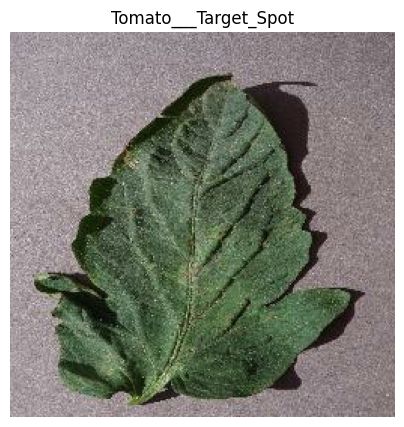

In [29]:
# Inspect a sample image

sample_image, sample_label = next(iter(dataset.take(1)))

print("SAMPLE IMAGE INSPECTION")
print("-----------------------")
print("Image dimensions:", sample_image.shape)
print("Image data type:", sample_image.dtype)
print("Minimum pixel value:", tf.reduce_min(sample_image).numpy())
print("Maximum pixel value:", tf.reduce_max(sample_image).numpy())
print("Sample label:", int(sample_label.numpy()))
print("Sample class:", class_names[int(sample_label.numpy())])

# Display the sample image
plt.figure(figsize=(5, 5))
plt.imshow(sample_image.numpy())
plt.title(class_names[int(sample_label.numpy())])
plt.axis("off")
plt.show()

### **2.3 Dataset Distribution**

Understanding the distribution of images across the different classes is important before training the model. This analysis helps identify whether some plant disease classes have significantly more or fewer images than others. Class distribution can affect model performance, particularly for classes with limited training examples.

In [30]:
# Calculate the number of images in each class
class_counts = np.zeros(total_classes, dtype=np.int64)

for _, label in dataset:
    class_counts[int(label.numpy())] += 1

# Create a DataFrame for easier analysis
class_distribution = pd.DataFrame({
    "Class": class_names,
    "Image Count": class_counts
})

# Sort the classes by image count
class_distribution = class_distribution.sort_values(
    by="Image Count",
    ascending=False
)

print("PLANTVILLAGE CLASS DISTRIBUTION")
print("--------------------------------")
print(class_distribution.to_string(index=False))

print("\nTotal images:", class_distribution["Image Count"].sum())
print("Total classes:", len(class_distribution))

PLANTVILLAGE CLASS DISTRIBUTION
--------------------------------
                                        Class  Image Count
     Orange___Haunglongbing_(Citrus_greening)         5507
       Tomato___Tomato_Yellow_Leaf_Curl_Virus         5357
                            Soybean___healthy         5090
                       Peach___Bacterial_spot         2297
                      Tomato___Bacterial_spot         2127
                         Tomato___Late_blight         1908
                      Squash___Powdery_mildew         1835
                  Tomato___Septoria_leaf_spot         1771
Tomato___Spider_mites Two-spotted_spider_mite         1676
                              Apple___healthy         1645
                             Tomato___healthy         1591
                          Blueberry___healthy         1502
                       Pepper,_bell___healthy         1477
                         Tomato___Target_Spot         1404
                 Grape___Esca_(Black_Measles)     

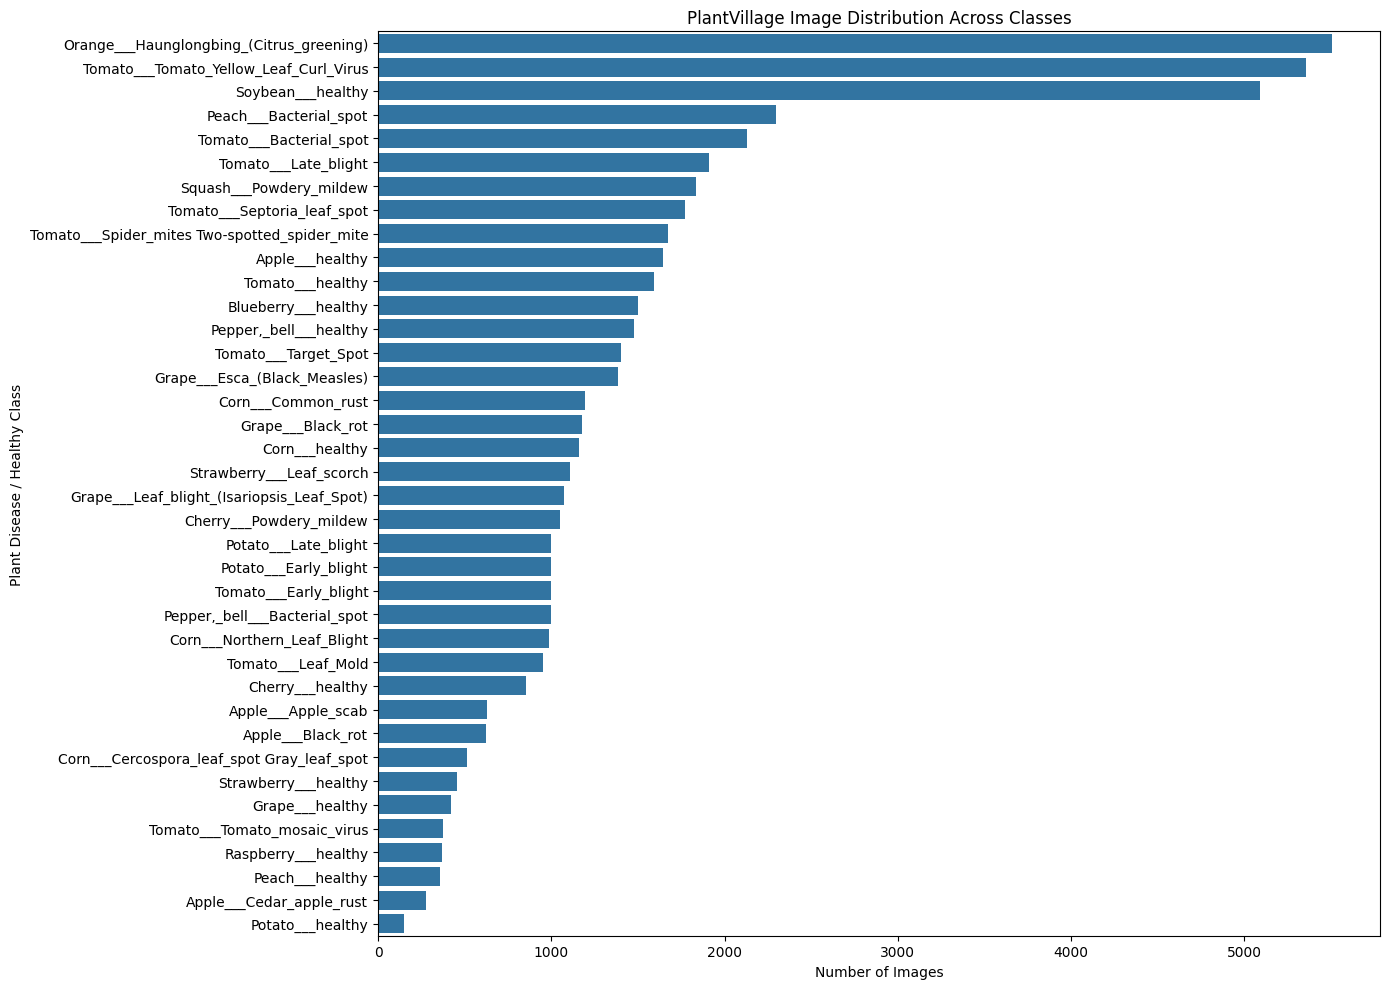

In [31]:
plt.figure(figsize=(14, 10))

sns.barplot(
    data=class_distribution,
    x="Image Count",
    y="Class"
)

plt.title("PlantVillage Image Distribution Across Classes")
plt.xlabel("Number of Images")
plt.ylabel("Plant Disease / Healthy Class")
plt.tight_layout()
plt.show()

### **Dataset Distribution Analysis**

The PlantVillage dataset contains 38 plant disease and healthy classes with different numbers of images per class. The distribution is not uniform, with some classes containing substantially more images than others.

The largest classes contain several thousand images, while some classes contain fewer than 500 images. This variation indicates a degree of class imbalance within the dataset.

This imbalance is important to consider during model development because classes with more training examples may have an advantage during learning, while classes with fewer examples may be more difficult for the model to classify correctly. Data augmentation, appropriate evaluation metrics, and model optimization will therefore be considered during later stages of the project.

### **2.4 Sample Visualization**

Visual inspection of the dataset provides an understanding of the appearance and variation of the plant images. Samples from different classes are displayed to examine differences in plant species, disease symptoms, leaf conditions, colors, backgrounds, and other visual characteristics.

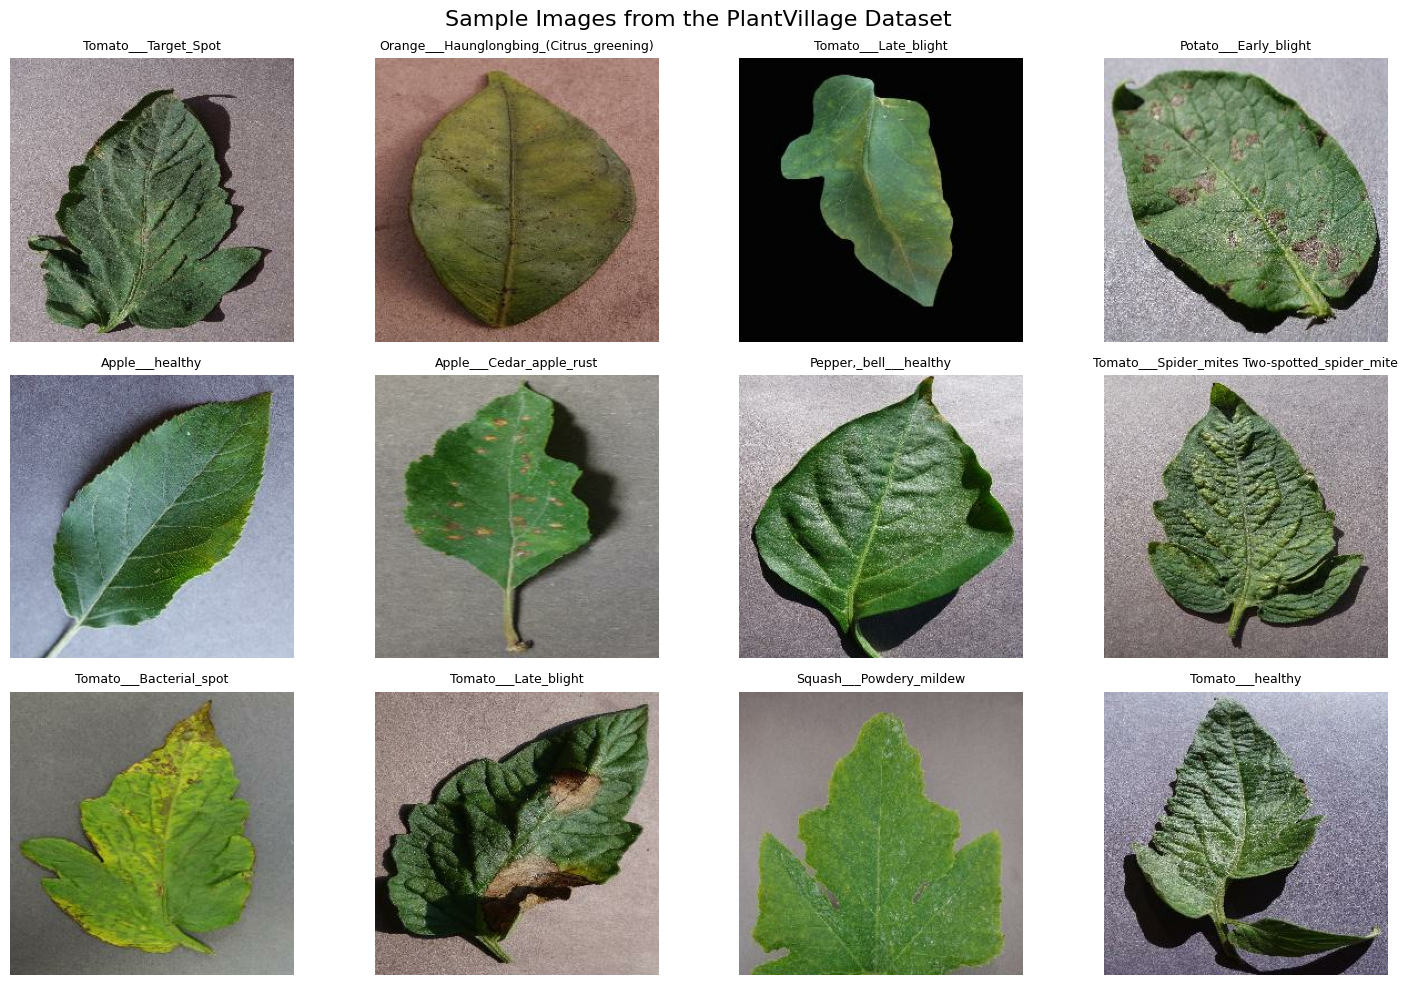

In [32]:
# Display sample images from different classes

plt.figure(figsize=(15, 10))

for i in range(12):
    image, label = next(iter(dataset.skip(i)))

    plt.subplot(3, 4, i + 1)
    plt.imshow(image.numpy().astype("uint8"))
    plt.title(class_names[int(label.numpy())], fontsize=9)
    plt.axis("off")

plt.suptitle("Sample Images from the PlantVillage Dataset", fontsize=16)
plt.tight_layout()
plt.show()

### **Sample Visualization Analysis**

The sample images show considerable visual variation across the PlantVillage classes. The images contain different plant species and leaf shapes, as well as different visible disease symptoms such as spots, discoloration, lesions, and changes in leaf texture.

The images also contain variations in background appearance, lighting, leaf orientation, and overall color. Healthy leaves generally appear visually different from diseased leaves, although some disease classes have similar visual characteristics.

These observations show that the model needs to learn relevant visual patterns rather than relying on a single characteristic such as color or leaf shape. The preprocessing and data augmentation stages will therefore be important for preparing the images for classification.

### **2.5 Image Characteristics**

Image characteristics provide additional information about the structure and visual properties of the dataset. In this section, image dimensions, pixel intensity, and color characteristics are examined to better understand the data before preprocessing.

In [33]:
# Analyze image dimensions

sample_images = []

for image, _ in dataset.take(100):
    sample_images.append(image.numpy())

image_shapes = [image.shape for image in sample_images]

print("Number of sampled images:", len(image_shapes))
print("Image dimensions:", image_shapes[0])
print("Unique image dimensions:", set(image_shapes))

Number of sampled images: 100
Image dimensions: (256, 256, 3)
Unique image dimensions: {(256, 256, 3)}


### **Image Dimensions Analysis**

The analysis of 100 sampled images shows that all sampled images have the same dimensions of 256 × 256 pixels with 3 color channels. This indicates that the dataset has a consistent image structure and does not require additional resizing for dimensional consistency at this stage.

The three channels represent the RGB color information contained in each image. This information will be used by the image classification model to learn visual patterns associated with the different plant disease classes.

In [34]:
# Analyze pixel intensity values

pixel_values = np.concatenate(
    [image.numpy().flatten() for image, _ in dataset.take(100)]
)

print("Minimum pixel value:", pixel_values.min())
print("Maximum pixel value:", pixel_values.max())
print("Mean pixel value:", pixel_values.mean())
print("Standard deviation:", pixel_values.std())

Minimum pixel value: 0
Maximum pixel value: 255
Mean pixel value: 114.33913772583008
Standard deviation: 51.51829925846734


### **Pixel Intensity Analysis**

The pixel intensity analysis shows that the sampled images contain values ranging from 0 to 255, with a mean pixel intensity of approximately 114.34 and a standard deviation of approximately 51.52.

The minimum and maximum values indicate that the images use the standard 8-bit pixel intensity range. The mean provides an indication of the overall brightness level of the sampled images, while the standard deviation shows variation in pixel intensity across the samples.

These raw pixel values will later be normalized during preprocessing so that the input values are placed on a smaller numerical scale before being provided to the model.

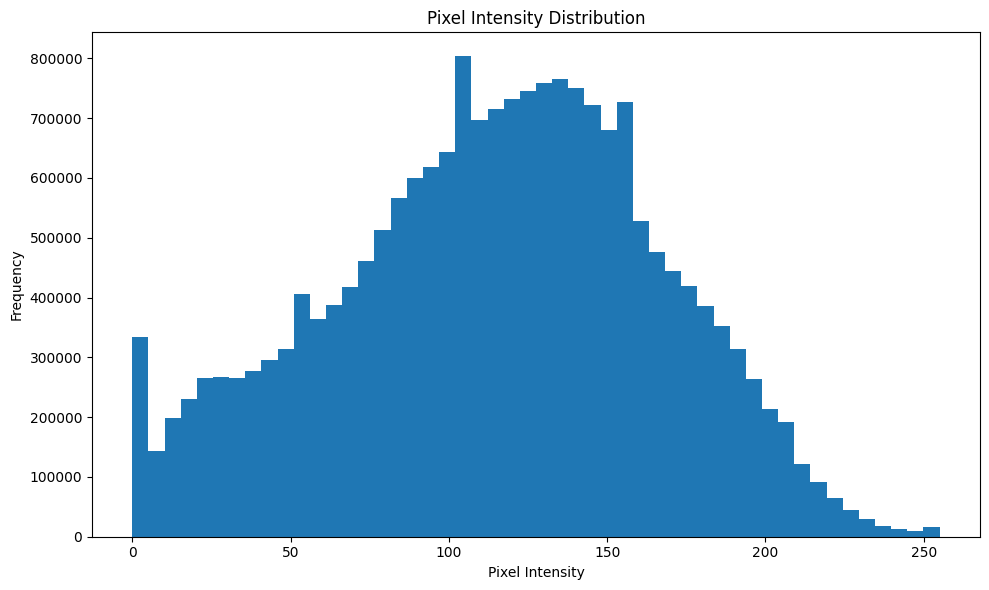

In [35]:
# Visualize pixel intensity distribution

plt.figure(figsize=(10, 6))

plt.hist(pixel_values, bins=50)

plt.title("Pixel Intensity Distribution")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

### **Pixel Distribution Interpretation**

The pixel intensity distribution shows that the sampled images contain pixel values across the full 0–255 range. Most pixel values are concentrated within the middle portion of this range, while relatively fewer pixels occur at the highest intensity values.

This distribution demonstrates that the dataset contains substantial variation in pixel intensities. Since the original pixel values are represented on a 0–255 scale, normalization will be applied during preprocessing to transform the values into a smaller numerical range suitable for model training.

In [36]:
# Analyze RGB color channels

channel_means = []

for image, _ in dataset.take(100):
    image_array = image.numpy()
    
    channel_means.append([
        image_array[:, :, 0].mean(),  # Red
        image_array[:, :, 1].mean(),  # Green
        image_array[:, :, 2].mean()   # Blue
    ])

channel_means = np.array(channel_means)

print("Average Red intensity:", channel_means[:, 0].mean())
print("Average Green intensity:", channel_means[:, 1].mean())
print("Average Blue intensity:", channel_means[:, 2].mean())

Average Red intensity: 116.59791885375977
Average Green intensity: 122.9140054321289
Average Blue intensity: 103.50548889160156


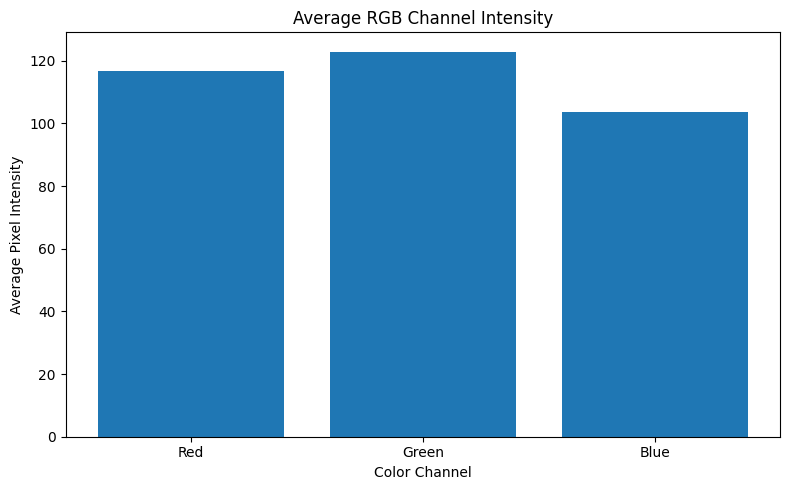

In [37]:
# Visualize average RGB channel intensity

channel_names = ["Red", "Green", "Blue"]
channel_values = channel_means.mean(axis=0)

plt.figure(figsize=(8, 5))

plt.bar(channel_names, channel_values)

plt.title("Average RGB Channel Intensity")
plt.xlabel("Color Channel")
plt.ylabel("Average Pixel Intensity")

plt.tight_layout()
plt.show()

### **RGB Channel Analysis**

The average RGB channel intensities calculated from 100 sampled images were approximately 116.60 for red, 122.91 for green, and 103.51 for blue. The green channel had the highest average intensity, while the blue channel had the lowest.

The differences between the channels indicate that color information is an important characteristic of the images. Since the dataset contains plant leaves and disease symptoms that can involve changes in color, the RGB information will be retained during preprocessing rather than converting the images to grayscale.

### **2.6 Feature Analysis: What Separates Healthy and Diseased Leaves?**

This section examines three features of the dataset to understand what the model has to learn:

1. **Crop and health-status distribution**: which crops dominate the dataset and how healthy and diseased images are split within each crop.
2. **Leaf colour**: the share of green pixels and the share of yellow or brown pixels in each image.
3. **Leaf texture**: the average edge strength in each image, which increases when a leaf has spots, lesions or uneven patches.

Some crops in PlantVillage contain only healthy images (for example Soybean) and some contain only diseased images (for example Orange). Comparing all healthy images with all diseased images would therefore mix crop differences with disease differences. For the colour and texture features, healthy and diseased leaves are compared **within the same crop**, using only the crops that contain both.

In [81]:
# Build a balanced sample and extract colour and texture features

SAMPLES_PER_CLASS = 40

sample_counts = np.zeros(total_classes, dtype=int)
feature_rows = []

for image, label in dataset:
    label = int(label.numpy())

    if sample_counts[label] >= SAMPLES_PER_CLASS:
        continue

    # Scale pixels to the 0-1 range
    img = tf.image.convert_image_dtype(image, tf.float32)
    r, g, b = img[..., 0], img[..., 1], img[..., 2]

    # Feature 2a: share of pixels where green is the strongest channel
    green_ratio = tf.reduce_mean(tf.cast((g > r) & (g > b), tf.float32))

    # Feature 2b: share of yellow or brown pixels (red at least as strong as green, clearly above blue)
    brown_ratio = tf.reduce_mean(tf.cast((r >= g) & (r - b > 0.15), tf.float32))

    # Feature 3: texture as the average Sobel edge strength of the grayscale image
    gray = tf.image.rgb_to_grayscale(img)[tf.newaxis, ...]
    edges = tf.image.sobel_edges(gray)
    texture = tf.reduce_mean(tf.sqrt(tf.reduce_sum(tf.square(edges), axis=-1)))

    class_name = class_names[label]

    feature_rows.append({
        "Class": class_name,
        "Crop": class_name.split("___")[0].replace("_", " ").replace(",", ""),
        "Status": "Healthy" if "healthy" in class_name else "Diseased",
        "Green ratio": float(green_ratio),
        "Yellow/brown ratio": float(brown_ratio),
        "Texture": float(texture)
    })

    sample_counts[label] += 1

    if sample_counts.min() >= SAMPLES_PER_CLASS:
        break

features_df = pd.DataFrame(feature_rows)

# Keep only crops that have both healthy and diseased images
status_per_crop = features_df.groupby("Crop")["Status"].nunique()
paired_crops = status_per_crop[status_per_crop == 2].index.tolist()
paired_df = features_df[features_df["Crop"].isin(paired_crops)]

print("Images analysed:", len(features_df))
print("Images per class:", SAMPLES_PER_CLASS)
print("Crops with both healthy and diseased images:", paired_crops)

Images analysed: 1520
Images per class: 40
Crops with both healthy and diseased images: ['Apple', 'Cherry', 'Corn', 'Grape', 'Peach', 'Pepper bell', 'Potato', 'Strawberry', 'Tomato']


#### **Feature 1: Crop and Health-Status Distribution**

IMAGES PER CROP
---------------
Status       Healthy  Diseased  Total  Classes  Share of dataset (%)
Crop                                                                
Tomato          1591     16568  18159       10                 33.44
Orange             0      5507   5507        1                 10.14
Soybean         5090         0   5090        1                  9.37
Grape            423      3639   4062        4                  7.48
Corn            1162      2690   3852        4                  7.09
Apple           1645      1526   3171        4                  5.84
Peach            360      2297   2657        2                  4.89
Pepper bell     1477       997   2474        2                  4.56
Potato           152      2000   2152        3                  3.96
Cherry           854      1052   1906        2                  3.51
Squash             0      1835   1835        1                  3.38
Strawberry       456      1109   1565        2                  2.88
Bl

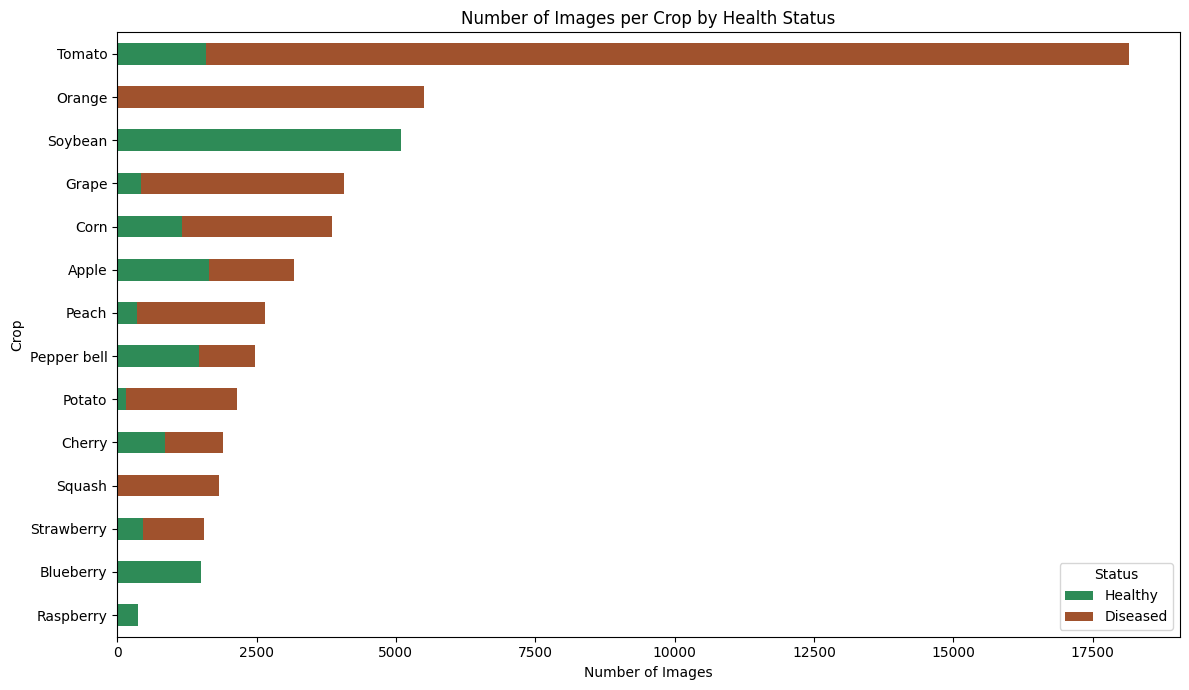

In [82]:
# Feature 1: images per crop, split by health status

crop_df = class_distribution.copy()
crop_df["Crop"] = crop_df["Class"].str.split("___").str[0].str.replace("_", " ").str.replace(",", "")
crop_df["Status"] = np.where(crop_df["Class"].str.contains("healthy"), "Healthy", "Diseased")

crop_summary = crop_df.pivot_table(
    index="Crop",
    columns="Status",
    values="Image Count",
    aggfunc="sum",
    fill_value=0
)[["Healthy", "Diseased"]]

crop_summary["Total"] = crop_summary.sum(axis=1)
crop_summary["Classes"] = crop_df.groupby("Crop")["Class"].count()
crop_summary["Share of dataset (%)"] = (crop_summary["Total"] / crop_summary["Total"].sum() * 100).round(2)
crop_summary = crop_summary.sort_values("Total", ascending=False)

print("IMAGES PER CROP")
print("---------------")
print(crop_summary.to_string())

print("\nOverall healthy images:", crop_summary["Healthy"].sum())
print("Overall diseased images:", crop_summary["Diseased"].sum())

crop_summary[["Healthy", "Diseased"]].iloc[::-1].plot(
    kind="barh",
    stacked=True,
    figsize=(12, 7),
    color=["seagreen", "sienna"]
)

plt.title("Number of Images per Crop by Health Status")
plt.xlabel("Number of Images")
plt.ylabel("Crop")
plt.legend(title="Status")
plt.tight_layout()
plt.show()

### **Interpretation of Feature 1: Crop and Health-Status Distribution**

The dataset is dominated by a single crop. **Tomato accounts for 18,159 images (33.4% of the dataset)** and 10 of the 38 classes. Together, Tomato, Orange (5,507 images) and Soybean (5,090 images) make up more than half of all images. In contrast, crops such as Raspberry (371 images) and Strawberry (1,565 images) are only lightly represented.

The dataset is also skewed towards diseased leaves, with **39,220 diseased images (72.2%)** compared with **15,083 healthy images (27.8%)**. The balance varies widely between crops. Orange and Squash contain only diseased images, while Soybean, Blueberry and Raspberry contain only healthy ones. Potato has only 152 healthy images against 2,000 diseased ones.

This tells two stories. First, the model sees far more tomato images than any other crop, but tomato also has the most disease classes to separate, which helps explain why most of the errors in Section 4.8 involve tomato diseases. Second, for crops like Orange or Soybean the model never sees the opposite health status, so it cannot learn to tell a healthy orange leaf from a diseased one. This is a limitation of the dataset that should be addressed during retraining, by uploading healthy and diseased images for these crops.

#### **Feature 2: Leaf Colour**

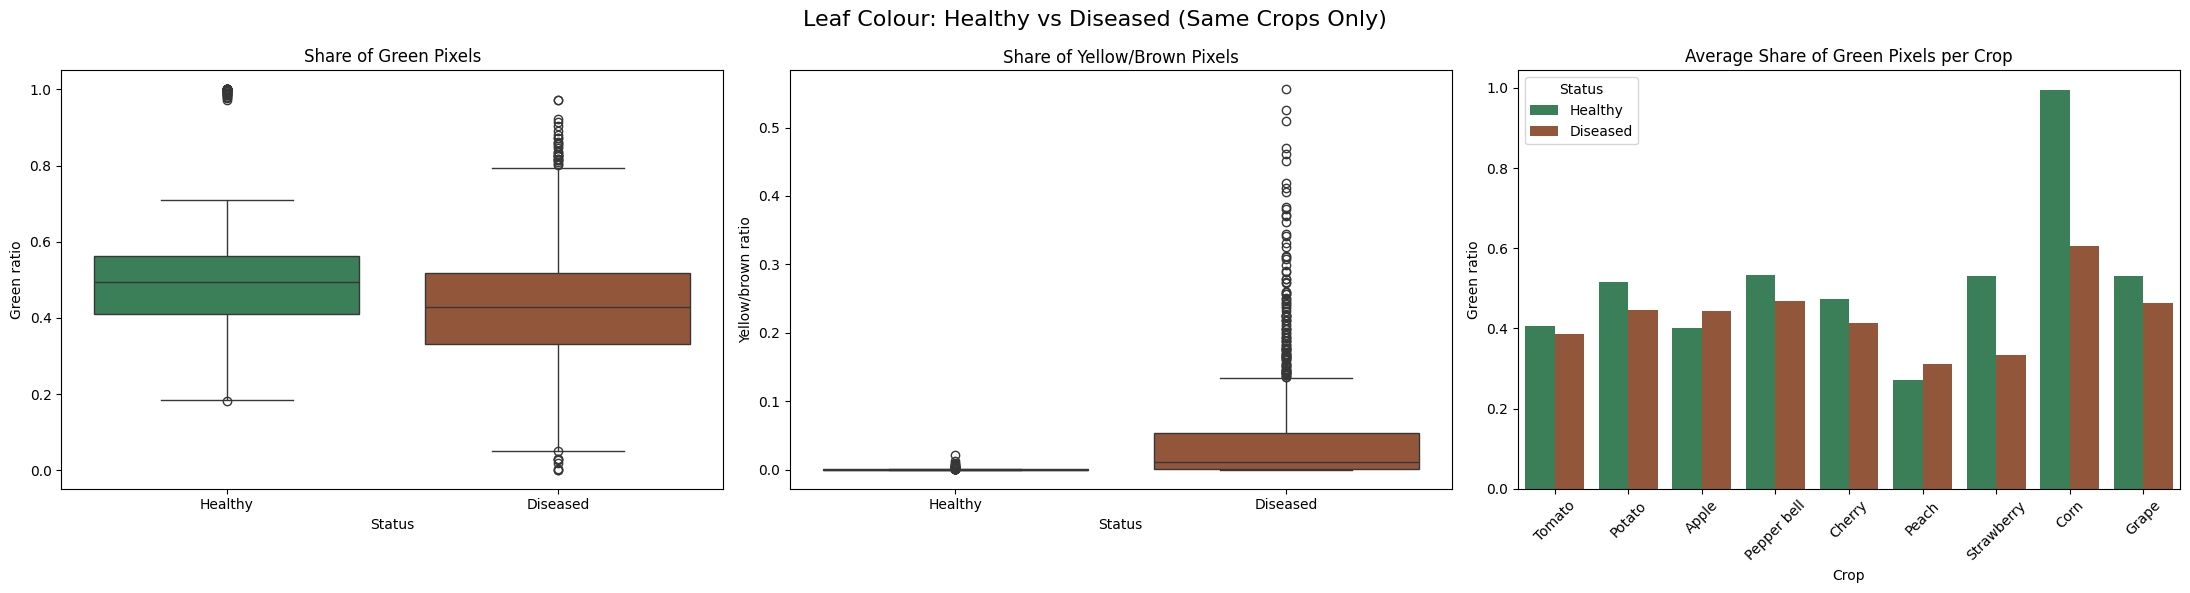

In [83]:
# Feature 2: green and yellow/brown pixel ratios, healthy vs diseased within the same crops

palette = {"Healthy": "seagreen", "Diseased": "sienna"}
order = ["Healthy", "Diseased"]

fig, axes = plt.subplots(1, 3, figsize=(22, 6))

sns.boxplot(data=paired_df, x="Status", y="Green ratio", hue="Status",
            order=order, palette=palette, legend=False, ax=axes[0])
axes[0].set_title("Share of Green Pixels")

sns.boxplot(data=paired_df, x="Status", y="Yellow/brown ratio", hue="Status",
            order=order, palette=palette, legend=False, ax=axes[1])
axes[1].set_title("Share of Yellow/Brown Pixels")

sns.barplot(data=paired_df, x="Crop", y="Green ratio", hue="Status",
            hue_order=order, palette=palette, errorbar=None, ax=axes[2])
axes[2].set_title("Average Share of Green Pixels per Crop")
axes[2].tick_params(axis="x", rotation=45)

plt.suptitle("Leaf Colour: Healthy vs Diseased (Same Crops Only)", fontsize=16)
plt.tight_layout()
plt.show()

### **Interpretation of Feature 2: Leaf Colour**

Leaf colour is the clearest visible difference between healthy and diseased leaves. Within the nine crops that contain both health statuses, healthy images have an average **green ratio of 51.75%**, compared with **43.50%** for diseased images.

The **yellow/brown ratio** shows an even stronger difference. Healthy leaves have almost no yellow or brown pixels (**0.05%** on average), while diseased leaves average **4.60%**. Diseased leaves have a higher yellow/brown ratio than healthy leaves in **all nine crops**, making this the most consistent feature in the analysis. The green ratio is lower for diseased leaves in seven of the nine crops, with Apple and Peach as exceptions.

The size of the colour change depends on the disease. Strawberry (16.52%), Peach (11.17%) and Corn (10.36%) diseased leaves show large yellow or brown areas, which matches diseases such as leaf scorch and blight that kill large patches of tissue. Diseased tomato leaves show only **1.78%** yellow/brown on average, because most tomato diseases appear as small dark spots rather than large discoloured areas. The boxplot also shows that many diseased images have very little yellow or brown, with a long tail of images where it covers a large part of the leaf.

The story is that colour helps the model detect disease, but it is not enough on its own. Tomato diseases have the weakest colour signal and the most classes, which matches the per-class results where tomato diseases were the hardest to separate.

#### **Feature 3: Leaf Texture**

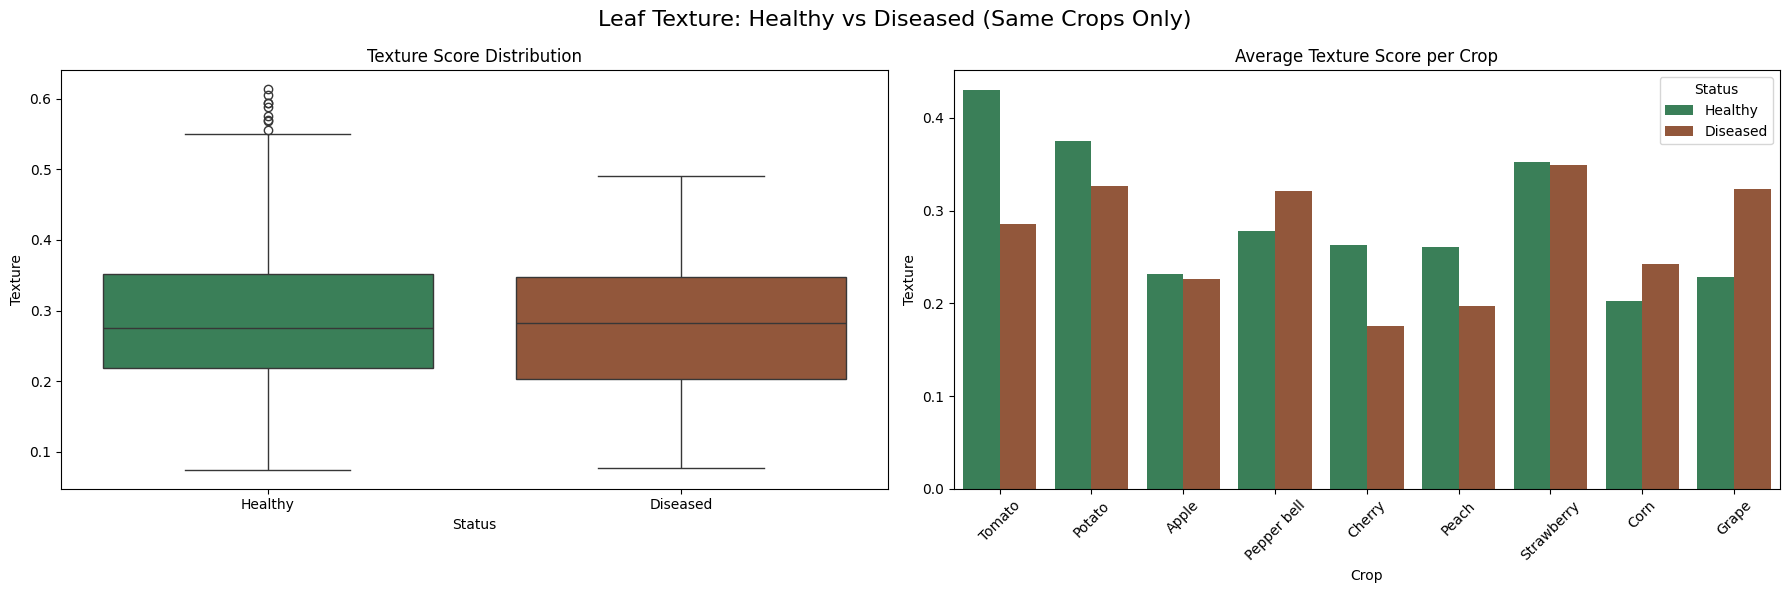

In [84]:
# Feature 3: texture (edge strength), healthy vs diseased within the same crops

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

sns.boxplot(data=paired_df, x="Status", y="Texture", hue="Status",
            order=order, palette=palette, legend=False, ax=axes[0])
axes[0].set_title("Texture Score Distribution")

sns.barplot(data=paired_df, x="Crop", y="Texture", hue="Status",
            hue_order=order, palette=palette, errorbar=None, ax=axes[1])
axes[1].set_title("Average Texture Score per Crop")
axes[1].tick_params(axis="x", rotation=45)

plt.suptitle("Leaf Texture: Healthy vs Diseased (Same Crops Only)", fontsize=16)
plt.tight_layout()
plt.show()

### **Interpretation of Feature 3: Leaf Texture**

The texture score was expected to be higher for diseased leaves, because spots and lesions add edges to the image. The results do not support this. Healthy leaves have an average texture score of **0.2913** and diseased leaves **0.2764**, which is almost the same, and the two boxplots overlap almost completely.

The per-crop results go in both directions. Diseased leaves have more texture in Grape (0.3232 vs 0.2284), Pepper bell (0.3210 vs 0.2775) and Corn (0.2422 vs 0.2028). Healthy leaves have more texture in Tomato (0.4297 vs 0.2849), Potato, Cherry and Peach. In Apple and Strawberry the values are nearly equal.

This happens because the texture score measures edges across the whole image. Leaf veins, serrated leaf edges, shadows and the background all add edges, and these are often stronger than the edges created by small disease spots. Healthy tomato leaves, for example, have strong veins and jagged edges, which gives them the highest texture score of any group.

This finding is useful even though the expected pattern did not appear. It shows that a simple, image-wide measurement cannot separate healthy and diseased leaves. The model needs to learn where texture occurs and what shape it has, for example a ringed lesion compared with a vein. This is what convolutional layers do, which supports the choice of a CNN such as MobileNetV2 for this task.

In [85]:
# Summary of colour and texture features

feature_cols = ["Green ratio", "Yellow/brown ratio", "Texture"]

print("AVERAGE FEATURE VALUES (same crops only)")
print("----------------------------------------")
print(paired_df.groupby("Status")[feature_cols].mean().loc[order].round(4).to_string())

print("\nAVERAGE FEATURE VALUES PER CROP")
print("-------------------------------")
print(paired_df.groupby(["Crop", "Status"])[feature_cols].mean().round(4).to_string())

AVERAGE FEATURE VALUES (same crops only)
----------------------------------------
          Green ratio  Yellow/brown ratio  Texture
Status                                            
Healthy        0.5175              0.0005   0.2913
Diseased       0.4350              0.0460   0.2764

AVERAGE FEATURE VALUES PER CROP
-------------------------------
                      Green ratio  Yellow/brown ratio  Texture
Crop        Status                                            
Apple       Diseased       0.4425              0.0128   0.2259
            Healthy        0.4003              0.0000   0.2318
Cherry      Diseased       0.4124              0.0078   0.1751
            Healthy        0.4725              0.0007   0.2632
Corn        Diseased       0.6053              0.1036   0.2422
            Healthy        0.9943              0.0013   0.2028
Grape       Diseased       0.4640              0.0526   0.3232
            Healthy        0.5321              0.0003   0.2284
Peach       Disease

### **Summary: What Story Does the Data Tell?**

The three features together explain both the strengths and the weaknesses of the model:

1. **The data is uneven.** Tomato dominates the dataset, most images are diseased, and some crops have only one health status.
2. **Colour is the strongest simple signal.** Diseased leaves consistently show less green and more yellow or brown, which helps the model detect disease.
3. **Texture alone is not enough.** Whole-image texture does not separate healthy and diseased leaves, so the model must learn local patterns such as lesion shape and spot arrangement.

The hardest cases are diseases on the same crop with weak colour signals, especially tomato diseases. This is exactly where the model makes most of its mistakes in Section 4.8, and where new data and retraining will be most valuable.

## **3. Data Preprocessing**

Data preprocessing prepares the PlantVillage images for model training. The preprocessing stage includes splitting the dataset into training, validation, and test sets, preparing the image dimensions, normalizing pixel values, applying data augmentation, and optimizing the datasets for efficient training.

### **3.1 Train/Validation/Test Split**

The PlantVillage dataset is divided into training, validation, and test sets before model development. The training set is used to learn the visual patterns associated with each plant disease class, the validation set is used to monitor model performance during training, and the test set is reserved for final evaluation.

An 80/10/10 split is used to provide sufficient data for training while maintaining separate datasets for validation and final testing. A fixed random seed is used to make the split reproducible.

In [38]:
# Define dataset split sizes
train_size = int(0.80 * total_images)
validation_size = int(0.10 * total_images)
test_size = total_images - train_size - validation_size

print("Training images:", train_size)
print("Validation images:", validation_size)
print("Test images:", test_size)
print("Total images:", train_size + validation_size + test_size)

Training images: 43442
Validation images: 5430
Test images: 5431
Total images: 54303


In [39]:
# Shuffle the dataset before splitting
shuffled_dataset = dataset.shuffle(
    buffer_size=10000,
    seed=42,
    reshuffle_each_iteration=False
)

# Create training, validation, and test datasets
train_dataset = shuffled_dataset.take(train_size)

remaining_dataset = shuffled_dataset.skip(train_size)

validation_dataset = remaining_dataset.take(validation_size)

test_dataset = remaining_dataset.skip(validation_size)

print("Dataset splitting completed successfully.")

Dataset splitting completed successfully.


In [40]:
# Verify the dataset splits

print("TRAINING SET")
print("Images:", train_size)

print("\nVALIDATION SET")
print("Images:", validation_size)

print("\nTEST SET")
print("Images:", test_size)

print("\nSPLIT SUMMARY")
print("Training:", f"{train_size / total_images * 100:.1f}%")
print("Validation:", f"{validation_size / total_images * 100:.1f}%")
print("Test:", f"{test_size / total_images * 100:.1f}%")

TRAINING SET
Images: 43442

VALIDATION SET
Images: 5430

TEST SET
Images: 5431

SPLIT SUMMARY
Training: 80.0%
Validation: 10.0%
Test: 10.0%


### **3.2 Image Resizing**

The original PlantVillage images have dimensions of 256 × 256 pixels with three RGB color channels. To match the expected input dimensions of the MobileNetV2 architecture, the images are resized to 224 × 224 pixels while retaining the three RGB channels.

Consistent input dimensions allow the images to be processed efficiently by the convolutional neural network.

In [41]:
# Define image resizing function

IMG_SIZE = (224, 224)

def resize_image(image, label):
    image = tf.image.resize(image, IMG_SIZE)
    return image, label

In [42]:
# Apply resizing to the training, validation, and test datasets

train_dataset = train_dataset.map(
    resize_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

validation_dataset = validation_dataset.map(
    resize_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_dataset = test_dataset.map(
    resize_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

print("Images resized to:", IMG_SIZE)

Images resized to: (224, 224)


In [43]:
# Verify the new image dimensions

sample_image, sample_label = next(iter(train_dataset.take(1)))

print("Resized image shape:", sample_image.shape)
print("Label:", sample_label.numpy())

Resized image shape: (224, 224, 3)
Label: 37


### **3.3 Pixel Normalization**

The pixel values in the PlantVillage dataset originally range from 0 to 255. To make the input values suitable for the MobileNetV2 model, the images are normalized using the preprocessing function provided by MobileNetV2.

This preprocessing scales the pixel values from the original range of 0–255 to a range of approximately -1 to 1. Normalization helps provide consistent input values and supports stable and efficient model training.

In [44]:
# Define MobileNetV2 preprocessing function

def normalize_image(image, label):
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)
    return image, label

In [45]:
# Apply MobileNetV2 normalization to the datasets

train_dataset = train_dataset.map(
    normalize_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

validation_dataset = validation_dataset.map(
    normalize_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_dataset = test_dataset.map(
    normalize_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

print("MobileNetV2 normalization applied successfully.")

MobileNetV2 normalization applied successfully.


In [46]:
# Verify normalized pixel values

sample_image, sample_label = next(iter(train_dataset.take(1)))

print("Minimum pixel value:", tf.reduce_min(sample_image).numpy())
print("Maximum pixel value:", tf.reduce_max(sample_image).numpy())
print("Mean pixel value:", tf.reduce_mean(sample_image).numpy())
print("Image shape:", sample_image.shape)

Minimum pixel value: -1.0
Maximum pixel value: 0.6196003
Mean pixel value: -0.19934289
Image shape: (224, 224, 3)


### **3.4 Data Augmentation**

Data augmentation is applied to the training images to increase the variety of examples available to the model. This helps the model learn disease-related visual patterns rather than memorizing specific images.

Random transformations such as horizontal flipping, rotation, and zooming are applied to the training data. Data augmentation is applied only to the training set, while the validation and test sets remain unchanged to provide an unbiased evaluation of the model.

In [47]:
# Define data augmentation layers

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
])

print("Data augmentation pipeline created successfully.")

Data augmentation pipeline created successfully.


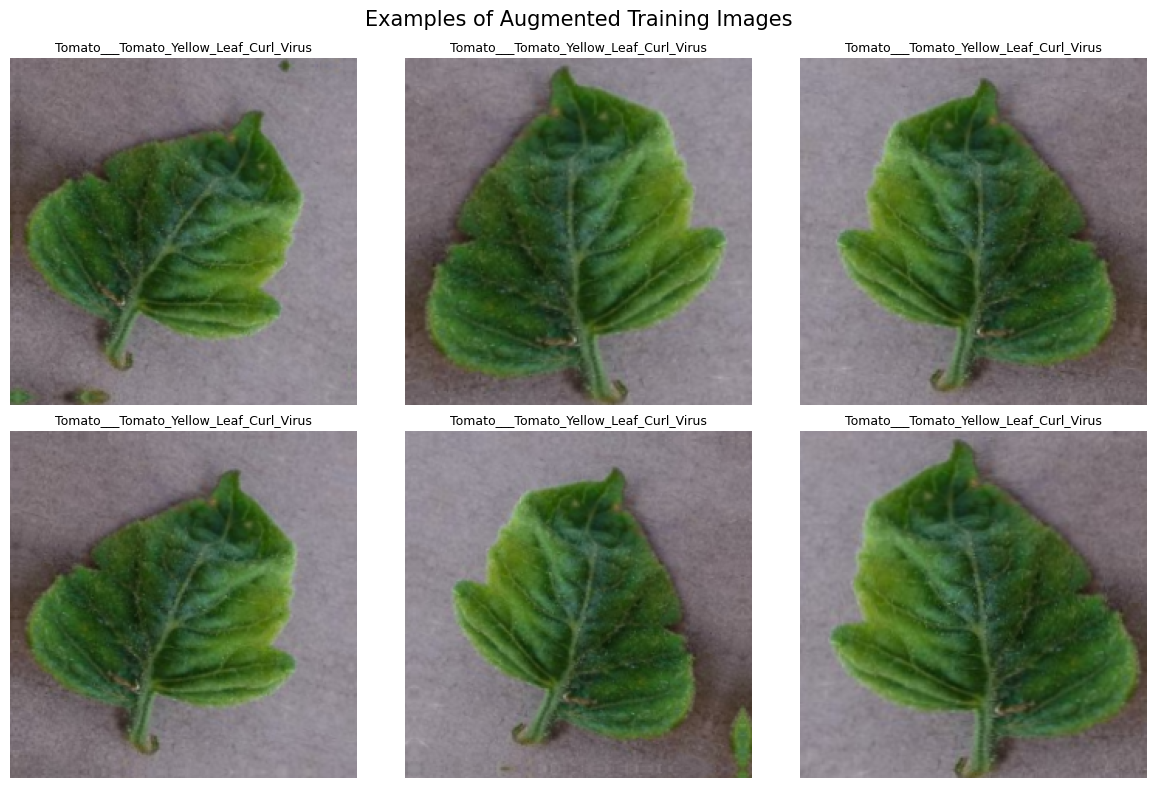

In [48]:
# Visualize augmented training images

sample_image, sample_label = next(iter(train_dataset.take(1)))

plt.figure(figsize=(12, 8))

for i in range(6):
    augmented_image = data_augmentation(
        tf.expand_dims(sample_image, axis=0),
        training=True
    )[0]

    plt.subplot(2, 3, i + 1)
    plt.imshow((augmented_image.numpy() + 1) / 2)
    plt.title(class_names[int(sample_label.numpy())], fontsize=9)
    plt.axis("off")

plt.suptitle("Examples of Augmented Training Images", fontsize=15)
plt.tight_layout()
plt.show()

### **3.5 Dataset Performance Optimization**

The datasets are optimized for efficient model training using batching and prefetching. Batching groups multiple images together so that the model can process several samples in one training step. Prefetching allows the input pipeline to prepare the next batch while the model is processing the current batch.

These optimizations help reduce input pipeline delays and improve the efficiency of GPU-based training.

In [49]:
# Define the batch size

BATCH_SIZE = 32

print("Batch size:", BATCH_SIZE)

Batch size: 32


In [50]:
# Define augmentation function for individual dataset images

def augment_image(image, label):
    # Add a batch dimension for the augmentation layers
    image = tf.expand_dims(image, axis=0)

    # Apply augmentation
    image = data_augmentation(image, training=True)

    # Remove the batch dimension
    image = tf.squeeze(image, axis=0)

    return image, label

In [51]:
# Apply data augmentation and optimize the dataset pipelines

train_dataset = train_dataset.map(
    augment_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_dataset = train_dataset.batch(BATCH_SIZE)
train_dataset = train_dataset.prefetch(tf.data.AUTOTUNE)


# Validation pipeline
validation_dataset = validation_dataset.batch(BATCH_SIZE)
validation_dataset = validation_dataset.prefetch(tf.data.AUTOTUNE)


# Test pipeline
test_dataset = test_dataset.batch(BATCH_SIZE)
test_dataset = test_dataset.prefetch(tf.data.AUTOTUNE)

print("Dataset performance optimization completed successfully.")

Dataset performance optimization completed successfully.


In [52]:
# Verify the final training dataset shape

sample_batch_images, sample_batch_labels = next(iter(train_dataset.take(1)))

print("Batch image shape:", sample_batch_images.shape)
print("Batch label shape:", sample_batch_labels.shape)
print("Batch size:", BATCH_SIZE)

Batch image shape: (32, 224, 224, 3)
Batch label shape: (32,)
Batch size: 32


## **4. Model Development**

### **4.1 Transfer Learning with MobileNetV2**

A MobileNetV2 model pretrained on the ImageNet dataset is used as the base model for PhytoGuard AI. Transfer learning allows the model to reuse visual features learned from a large image dataset while adapting the final classification layers to the 38 plant disease and healthy classes in the PlantVillage dataset.

The pretrained convolutional layers are initially frozen so that their learned features can be retained while the new classification layers are trained for the plant disease classification task.

In [53]:
# Load the pretrained MobileNetV2 base model

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze the pretrained layers
base_model.trainable = False

print("MobileNetV2 base model loaded successfully.")
print("Number of layers:", len(base_model.layers))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 base model loaded successfully.
Number of layers: 154


### **4.2 Classification Head**

A new classification head is added on top of the pretrained MobileNetV2 base model. Global average pooling is used to reduce the spatial dimensions of the extracted features, followed by dropout to reduce overfitting. A final dense layer with 38 output units and softmax activation produces the probability of each plant disease or healthy class.

In [54]:
# Build the classification head

inputs = tf.keras.Input(shape=(224, 224, 3))

x = base_model(inputs, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.2)(x)

outputs = tf.keras.layers.Dense(
    total_classes,
    activation="softmax"
)(x)

model = tf.keras.Model(inputs, outputs)

print("Model created successfully.")
print("Number of output classes:", total_classes)

Model created successfully.
Number of output classes: 38


In [55]:
# Display the model architecture

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,306,662 (8.80 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### **4.3 Model Compilation**

The model is compiled using the Adam optimizer and sparse categorical cross-entropy loss. Adam provides adaptive learning rates during training, while sparse categorical cross-entropy is appropriate because each image is assigned to one of the 38 classes using an integer class label.

Accuracy is included as an initial performance metric for monitoring the model during training.

In [56]:
# Compile the model

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


### **4.4 Model Training**

The MobileNetV2 model is trained using the prepared training dataset while the validation dataset is used to monitor performance during training. Early stopping is used to prevent unnecessary training and reduce overfitting. The model training process is monitored using training and validation loss and accuracy.

In [57]:
# Define training callbacks

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "phytoguard_mobilenetv2_best.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max"
)

print("Training callbacks created successfully.")

Training callbacks created successfully.


In [58]:
# Train the MobileNetV2 model

EPOCHS = 7

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS,
    callbacks=[
        early_stopping,
        model_checkpoint
    ]
)

Epoch 1/7
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 284s 196ms/step - accuracy: 0.6075 - loss: 1.5724 - val_accuracy: 0.8486 - val_loss: 0.7288
Epoch 2/7
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 256s 186ms/step - accuracy: 0.8439 - loss: 0.6282 - val_accuracy: 0.8888 - val_loss: 0.4623
Epoch 3/7
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 255s 186ms/step - accuracy: 0.8836 - loss: 0.4465 - val_accuracy: 0.9037 - val_loss: 0.3662
Epoch 4/7
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 255s 186ms/step - accuracy: 0.9002 - loss: 0.3654 - val_accuracy: 0.9153 - val_loss: 0.3136
Epoch 5/7
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 262s 185ms/step - accuracy: 0.9120 - loss: 0.3176 - val_accuracy: 0.9219 - val_loss: 0.2820
Epoch 6/7
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 255s 186ms/step - accuracy: 0.9195 - loss: 0.2839 - val_accuracy: 0.9276 - val_loss: 0.2602
Epoch 7/7
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 253s 185ms/step - accuracy: 0.9247 - loss: 0.2607 - val_accuracy: 0.9302 - val_loss: 0.2435


### **4.5 Training Performance Visualization**

The training history is visualized using accuracy and loss curves for the training and validation datasets. These plots provide a visual representation of how the model learned over the training epochs and help identify potential overfitting or underfitting.

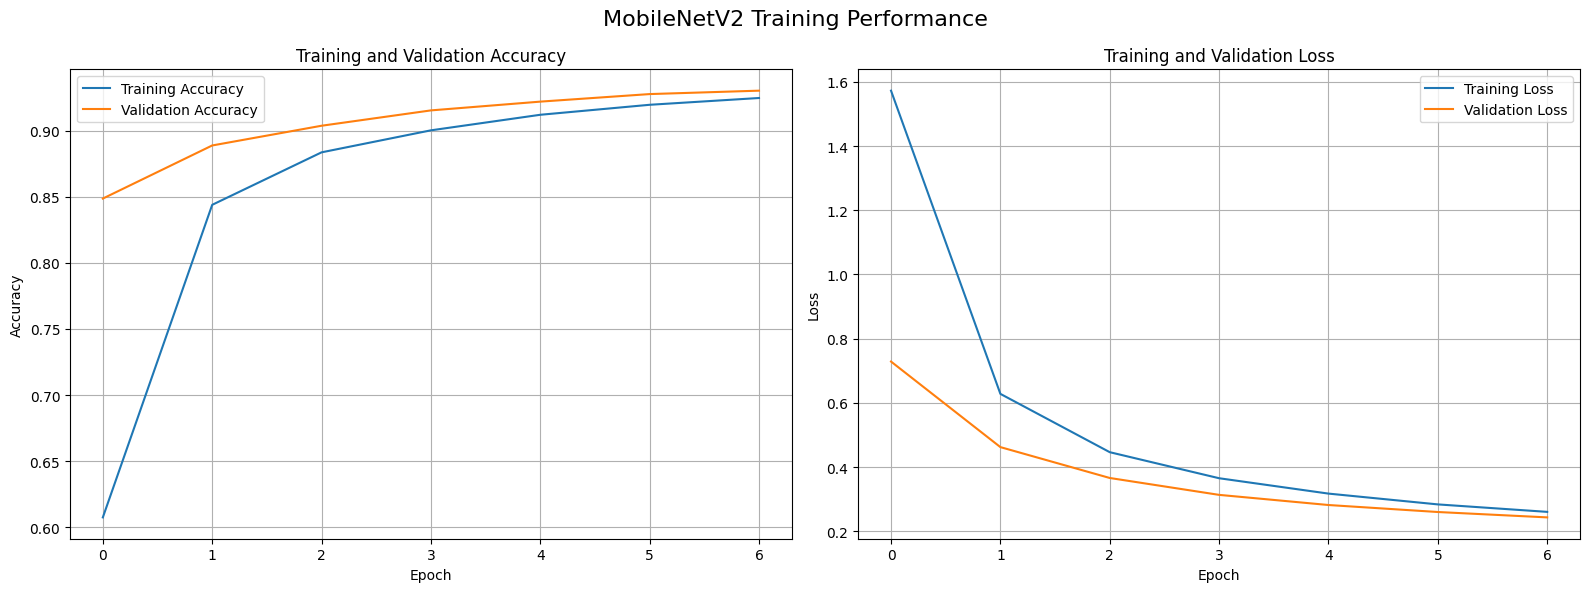

In [59]:
# Plot training history side by side

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Accuracy plot
axes[0].plot(history.history["accuracy"], label="Training Accuracy")
axes[0].plot(history.history["val_accuracy"], label="Validation Accuracy")
axes[0].set_title("Training and Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Loss plot
axes[1].plot(history.history["loss"], label="Training Loss")
axes[1].plot(history.history["val_loss"], label="Validation Loss")
axes[1].set_title("Training and Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.suptitle("MobileNetV2 Training Performance", fontsize=16)
plt.tight_layout()
plt.show()

### **Interpretation of Training Performance**

During the first training phase, only the new classification head was trained while the MobileNetV2 base remained frozen. Over seven epochs, training accuracy rose from **60.75% to 92.47%** and validation accuracy rose from **84.86% to 93.02%**. Validation loss fell steadily from **0.7288 to 0.2435**.

Validation loss decreased in every epoch and never started rising again, so there is **no evidence of overfitting** in this phase. The curves were also still improving at epoch 7, which suggests the frozen model had not fully converged and that further training could add more accuracy.

Validation accuracy was higher than training accuracy in every epoch. This is expected here for two reasons. Training images pass through data augmentation and dropout, which make them harder to classify, while validation images do not. Keras also reports training accuracy as an average across the whole epoch, including the early batches when the model was weaker.

These results show that the pretrained ImageNet features already transfer well to plant leaf images, and they give a strong starting point for fine-tuning.

### **4.6 Fine-Tuning MobileNetV2**

After training the classification head, fine-tuning is performed to allow the model to adapt some of the pretrained MobileNetV2 features specifically to plant disease images. The lower layers remain frozen because they capture general visual features, while the later layers are unfrozen and trained using a smaller learning rate.

A lower learning rate is used during fine-tuning to make small adjustments to the pretrained weights and reduce the risk of damaging the useful features learned from ImageNet.

In [60]:
# Unfreeze the top layers of MobileNetV2 for fine-tuning

base_model.trainable = True

# Keep the earlier layers frozen and fine-tune only the top 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Recompile with a smaller learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

print("Fine-tuning configuration completed.")
print("Trainable layers:", sum(layer.trainable for layer in base_model.layers))
print("Total layers:", len(base_model.layers))

Fine-tuning configuration completed.
Trainable layers: 30
Total layers: 154


In [61]:
# Fine-tune the model

FINE_TUNE_EPOCHS = 3

fine_tune_history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=[
        early_stopping,
        model_checkpoint
    ]
)

Epoch 1/3


E0000 00:00:1795504743.880715     374 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1357/1358 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step - accuracy: 0.8165 - loss: 0.6657

E0000 00:00:1795504999.764133     372 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1358/1358 ━━━━━━━━━━━━━━━━━━━━ 304s 208ms/step - accuracy: 0.8824 - loss: 0.4112 - val_accuracy: 0.9409 - val_loss: 0.1917
Epoch 2/3
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 271s 197ms/step - accuracy: 0.9381 - loss: 0.1989 - val_accuracy: 0.9529 - val_loss: 0.1532
Epoch 3/3
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 269s 196ms/step - accuracy: 0.9531 - loss: 0.1498 - val_accuracy: 0.9597 - val_loss: 0.1291


### **Interpretation of Fine-Tuning Results**

Fine-tuning the top 30 layers of MobileNetV2 with a learning rate of 1e-5 gave a clear improvement. Validation accuracy increased from **93.02%** at the end of the first phase to **95.97%** after three fine-tuning epochs, and validation loss dropped from **0.2435 to 0.1291**.

Training accuracy started lower at **88.24%** in the first fine-tuning epoch. Unfreezing pretrained layers briefly disturbs the weights the model had settled on. The model recovered quickly, reaching **95.31%** by the third epoch.

Validation accuracy stayed above training accuracy in all three epochs, and validation loss kept falling. The model is therefore still generalising well and has not started to memorise the training images.

Fine-tuning helped because the later layers of MobileNetV2 hold more task-specific features. Adjusting them allowed the model to focus on details that matter for plant disease, such as lesion shape, spotting patterns and leaf discolouration, instead of relying only on general ImageNet features.

### **4.7 Final Model Evaluation**

The final model is evaluated using the unseen test dataset. Multiple evaluation metrics are used to provide a more complete assessment of the model's classification performance.

The evaluation includes **loss, accuracy, precision, recall, and F1-score**. Accuracy measures the overall proportion of correctly classified images, while precision measures how often the model's predictions for a class are correct. Recall measures the model's ability to correctly identify images belonging to each class, and the F1-score provides a balance between precision and recall.

Because the PlantVillage dataset contains an imbalanced distribution of classes, weighted precision, recall, and F1-score are used so that the contribution of each class reflects its number of samples.

In [62]:
# Evaluate the fine-tuned model on the test dataset

test_loss, test_accuracy = model.evaluate(test_dataset, verbose=1)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

170/170 ━━━━━━━━━━━━━━━━━━━━ 22s 56ms/step - accuracy: 0.9611 - loss: 0.1262
Test Loss: 0.1261705756187439
Test Accuracy: 0.9611489772796631


In [63]:
# Generate predictions for the test dataset
y_true = []
y_pred = []

for images, labels in test_dataset:
    predictions = model.predict(images, verbose=0)
    
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

# Calculate weighted evaluation metrics
test_precision = precision_score(
    y_true,
    y_pred,
    average="weighted"
)

test_recall = recall_score(
    y_true,
    y_pred,
    average="weighted"
)

test_f1 = f1_score(
    y_true,
    y_pred,
    average="weighted"
)

print("Test Precision:", test_precision)
print("Test Recall:", test_recall)
print("Test F1-Score:", test_f1)

Test Precision: 0.962015758488727
Test Recall: 0.9611489596759345
Test F1-Score: 0.9603516024190989


### **Interpretation of Final Evaluation**

On the unseen test set of 5,431 images, the fine-tuned model achieved a **test accuracy of 96.11%** with a **test loss of 0.1262**. The weighted precision was **96.20%**, the weighted recall was **96.11%**, and the weighted F1-score was **96.04%**.

The test accuracy is very close to the final validation accuracy of 95.97%. This shows the model performs just as well on images it never saw during training or tuning, so it generalises well.

A precision of 96.20% means that when the model predicts a disease or healthy class, it is correct about 96 times out of 100. Weighted recall is always equal to accuracy, so it adds no extra information here. The F1-score of 96.04% confirms a good balance between precision and recall.

Weighted averages give more influence to the large classes, so they can hide weaker performance on small classes such as Potato___healthy (152 images) or Apple___Cedar_apple_rust (275 images). The per-class report and confusion matrix in the next section check how the model performs on each individual class.

### **4.8 Per-Class Evaluation**

Overall metrics can hide weak performance on individual classes, especially in an imbalanced dataset like PlantVillage. This section looks at each class separately using a classification report, compares macro and weighted averages, visualises the confusion matrix, and identifies the classes the model most often confuses.

Macro averages give every class equal weight, so they show how well the model handles small classes. Weighted averages give larger classes more influence.

In [77]:
# Per-class classification report

report = classification_report(
    y_true,
    y_pred,
    labels=list(range(total_classes)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

# Keep only the 38 class rows and sort from weakest to strongest
per_class_df = report_df.iloc[:total_classes].copy()
per_class_df["support"] = per_class_df["support"].astype(int)
per_class_df = per_class_df.sort_values("f1-score")

print("TEST SET COVERAGE")
print("-----------------")
print("Classes present in test set:", (per_class_df["support"] > 0).sum(), "of", total_classes)
print("Smallest class in test set:", per_class_df["support"].min(), "images")

print("\nMACRO AVERAGE (every class counts equally)")
print("------------------------------------------")
print(report_df.loc["macro avg", ["precision", "recall", "f1-score"]].round(4).to_string())

print("\nWEIGHTED AVERAGE (larger classes count more)")
print("--------------------------------------------")
print(report_df.loc["weighted avg", ["precision", "recall", "f1-score"]].round(4).to_string())

print("\n10 WEAKEST CLASSES BY F1-SCORE")
print("------------------------------")
print(per_class_df.head(10).round(4).to_string())

TEST SET COVERAGE
-----------------
Classes present in test set: 38 of 38
Smallest class in test set: 18 images

MACRO AVERAGE (every class counts equally)
------------------------------------------
precision    0.9563
recall       0.9487
f1-score     0.9507

WEIGHTED AVERAGE (larger classes count more)
--------------------------------------------
precision    0.9620
recall       0.9611
f1-score     0.9604

10 WEAKEST CLASSES BY F1-SCORE
------------------------------
                                               precision  recall  f1-score  support
Tomato___Early_blight                             0.9821  0.5670    0.7190       97
Corn___Cercospora_leaf_spot Gray_leaf_spot        0.7755  0.7917    0.7835       48
Tomato___Target_Spot                              0.8403  0.8231    0.8316      147
Tomato___Leaf_Mold                                0.8352  0.9048    0.8686       84
Corn___Northern_Leaf_Blight                       0.9053  0.8687    0.8866       99
Tomato___Septoria_leaf_

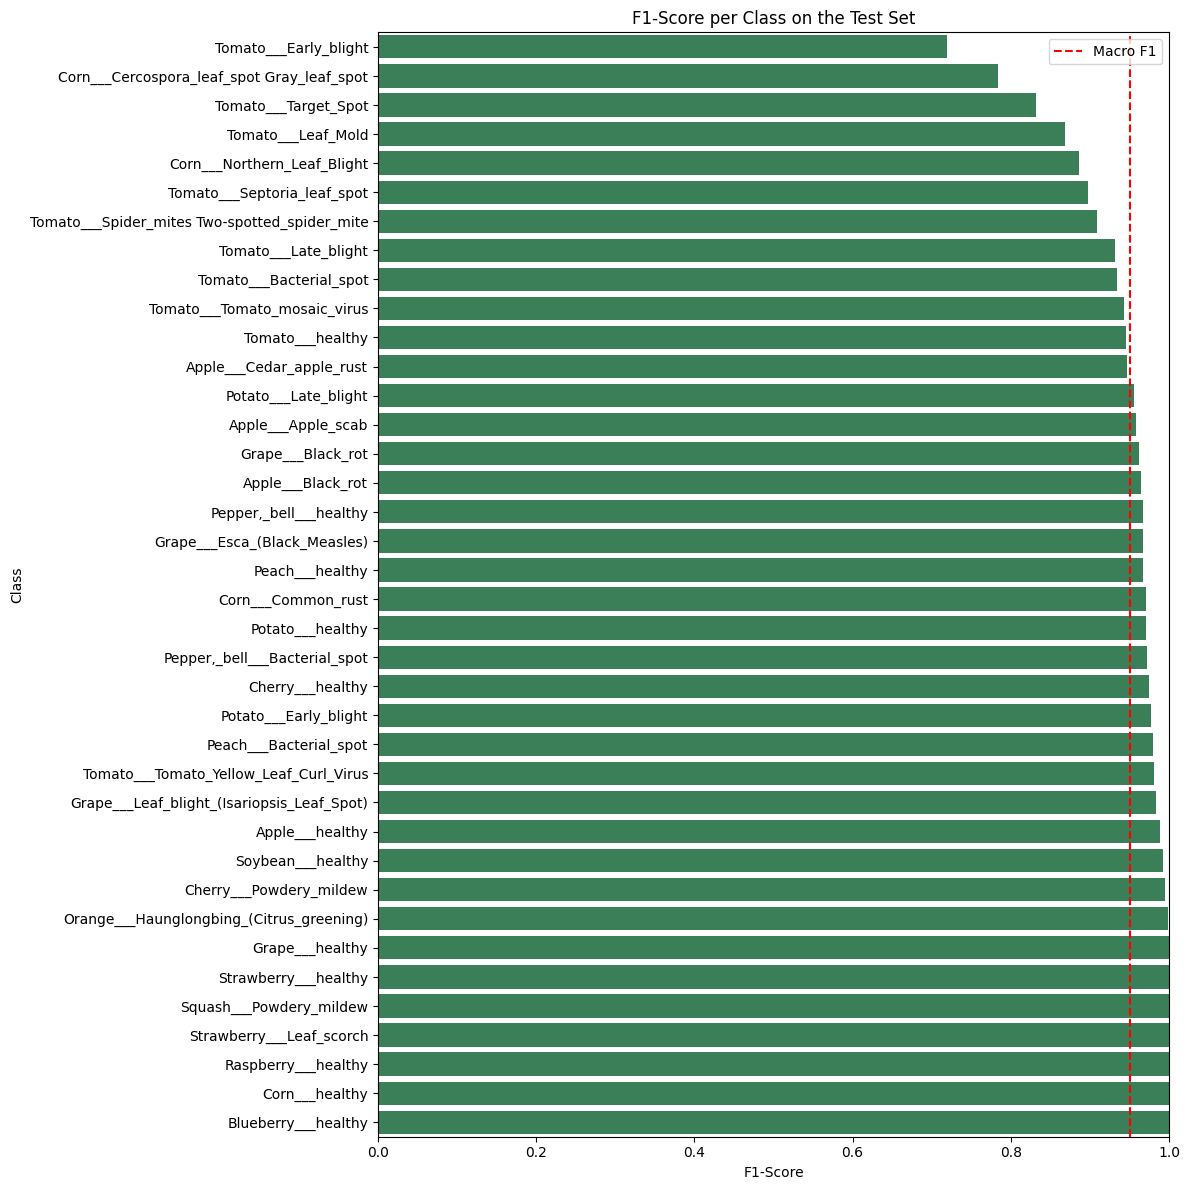

In [78]:
# Visualise F1-score for every class

plt.figure(figsize=(12, 12))

sns.barplot(
    x=per_class_df["f1-score"],
    y=per_class_df.index,
    color="seagreen"
)

plt.axvline(report_df.loc["macro avg", "f1-score"], color="red", linestyle="--", label="Macro F1")
plt.title("F1-Score per Class on the Test Set")
plt.xlabel("F1-Score")
plt.ylabel("Class")
plt.xlim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

### **Interpretation of Per-Class Performance**

All 38 classes are represented in the test set, with the smallest class containing 18 images, so every class was evaluated.

The **macro F1-score is 95.07%**, compared with a **weighted F1-score of 96.04%**. Macro precision is 95.63% and macro recall is 94.87%. The gap between the two averages is only about one percentage point, which means the model performs almost as well on small classes as on large ones. Class imbalance therefore has only a small effect on overall performance.

The weakest classes tell a different story. Seven of the ten lowest F1-scores belong to **tomato diseases**, and two belong to **corn leaf diseases**. These are diseases on the same crop that produce similar spots, lesions and discolouration. The main difficulty for the model is visual similarity between diseases, not the number of training images.

The clearest example is **Tomato___Early_blight**, with an F1-score of **71.90%**. Its precision is very high at **98.21%**, so when the model predicts Early blight it is almost always correct. However, its recall is only **56.70%**, meaning the model missed about 43% of the Early blight leaves in the test set and assigned them to other classes. This matches the uploaded field image in Section 5.4, which showed signs of Early blight but was predicted as Late blight.

**Corn___Cercospora_leaf_spot Gray_leaf_spot** is the second weakest class, with an F1-score of **78.35%**. It is one of the smaller classes (48 test images), and its symptoms resemble other corn leaf diseases, so here both limited data and visual similarity likely play a part.

From a practical point of view, low recall for a disease is the more serious error, because a farmer may not treat a sick plant. Improving Early blight recall is therefore the most valuable target for future retraining, for example by adding more Early blight images, especially field photos.

The F1-score chart makes this pattern easy to see. Seven classes reach an F1-score of about 1.00, mostly healthy leaves such as Blueberry, Corn, Raspberry and Strawberry, along with diseases that have very distinctive symptoms, such as Squash Powdery mildew and Strawberry Leaf scorch. Potato___healthy, the smallest class in the dataset with only 152 images, still reaches about 0.97. In contrast, almost all the classes below the macro F1 line are tomato or corn diseases. The model's weaknesses are concentrated in a small group of visually similar diseases rather than spread across the dataset.


### **Confusion Matrix**

The confusion matrix compares the actual class of each test image (rows) with the class the model predicted (columns). Each row is normalised so that it shows the share of that class predicted as each label. A strong model shows a dark diagonal, and any dark cells off the diagonal reveal classes the model confuses.

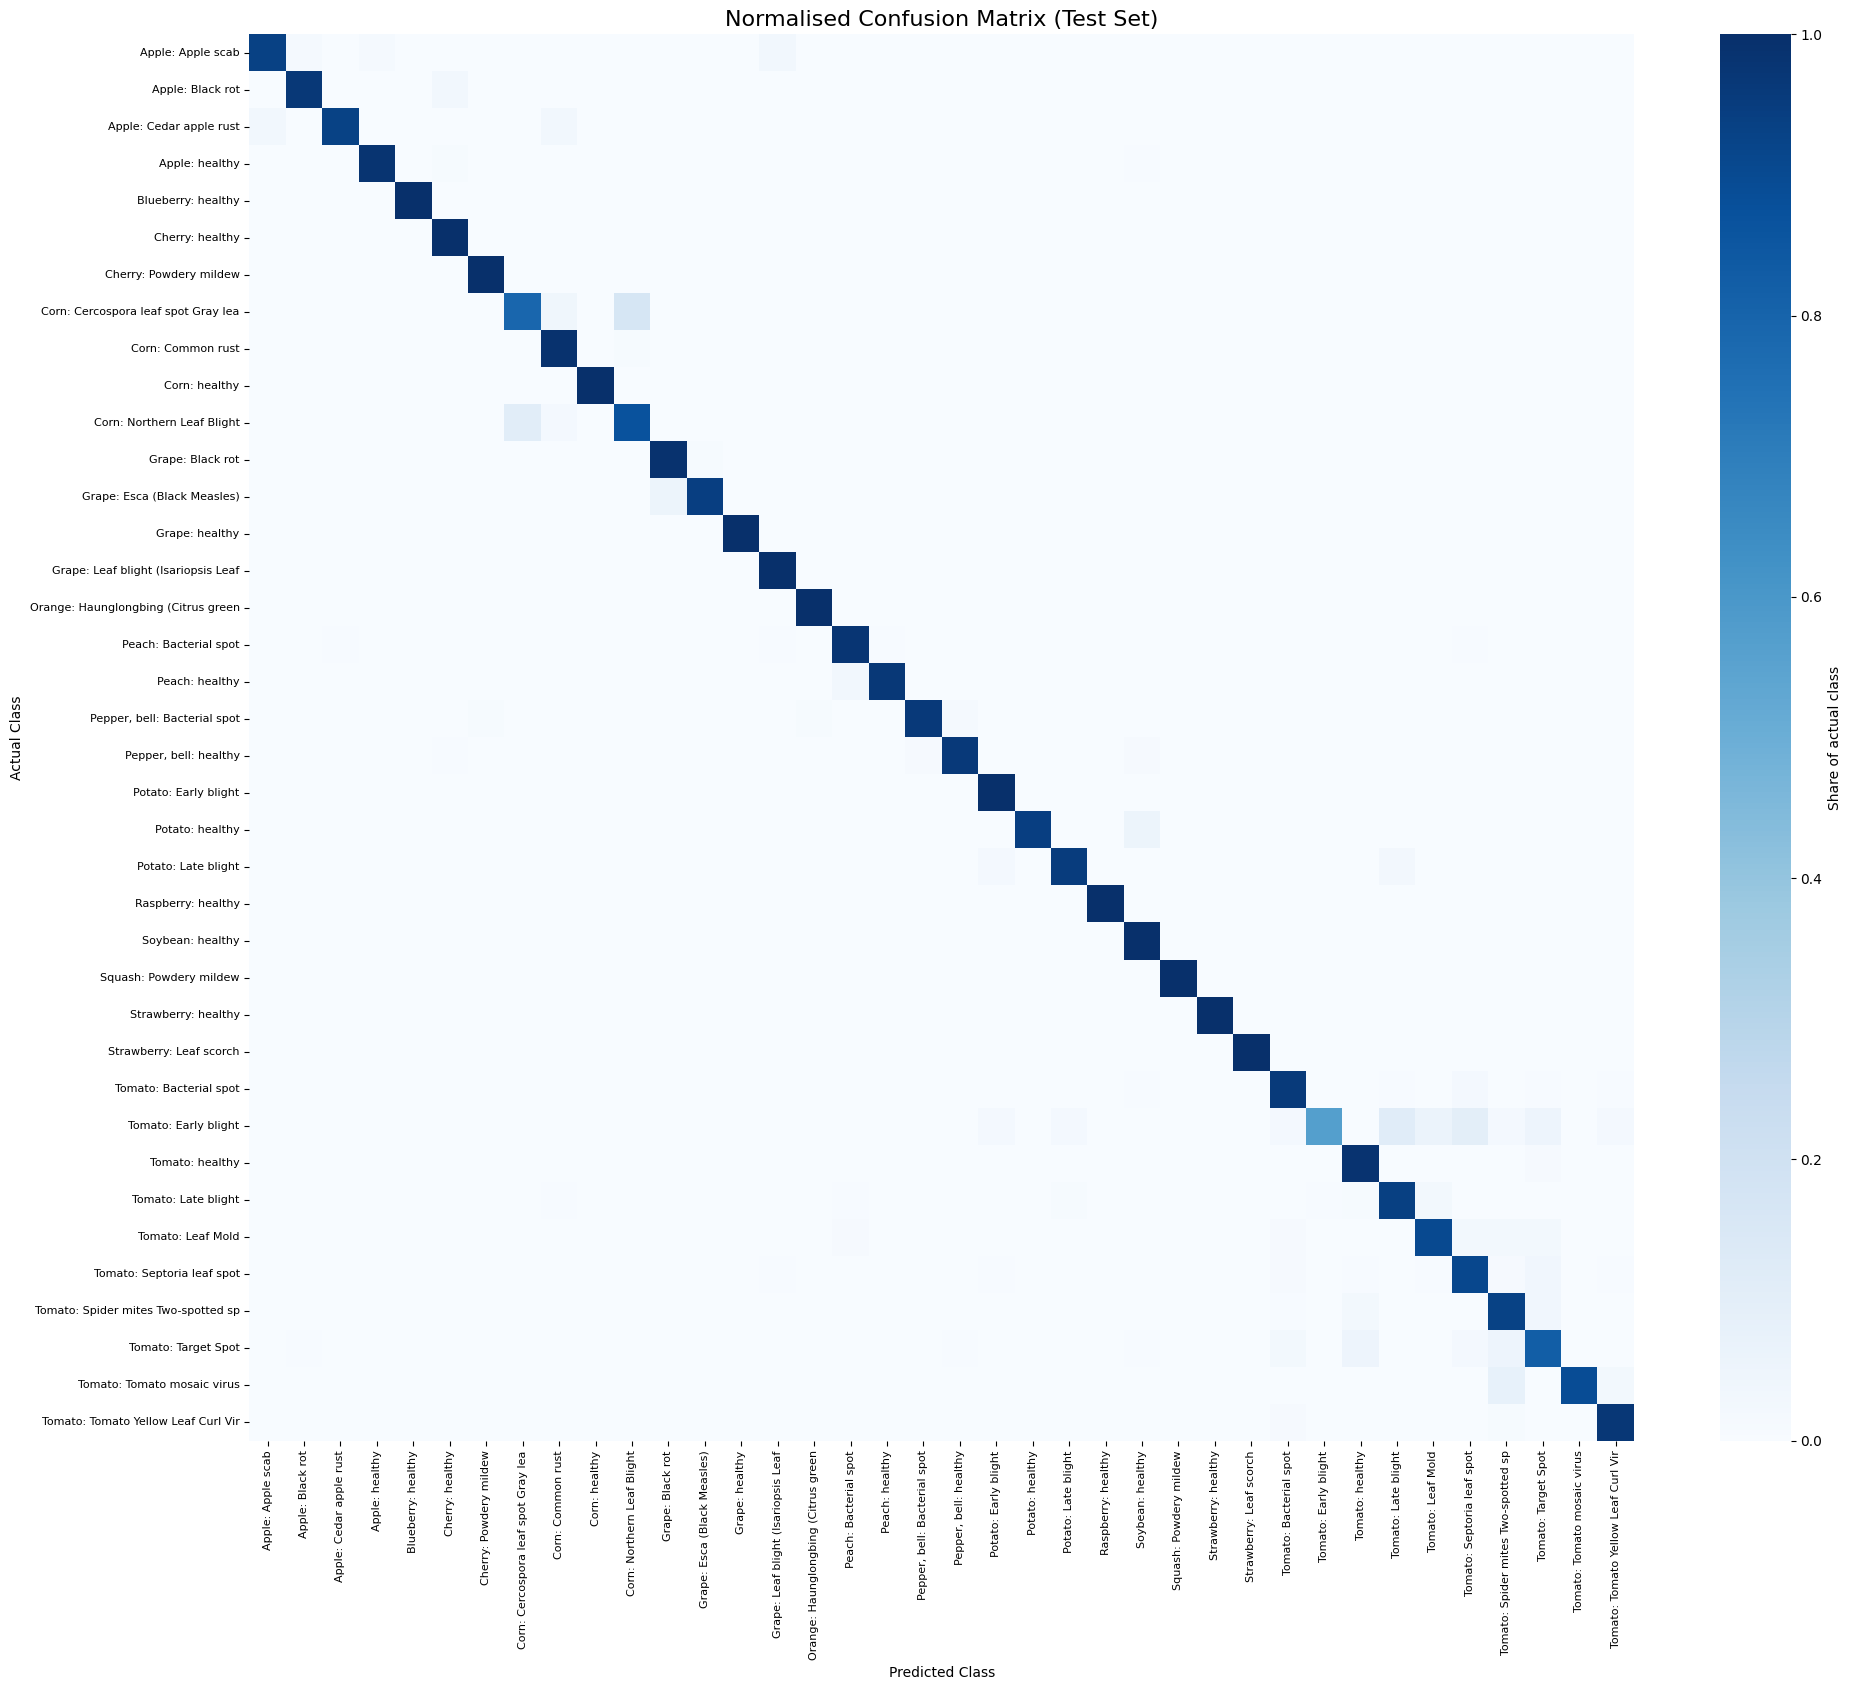

In [79]:
# Normalised confusion matrix

cm = confusion_matrix(y_true, y_pred, labels=list(range(total_classes)))

row_totals = cm.sum(axis=1, keepdims=True)
cm_normalised = np.divide(
    cm.astype(float),
    row_totals,
    out=np.zeros_like(cm, dtype=float),
    where=row_totals != 0
)

# Shorter labels so the axes stay readable
short_names = [name.replace("___", ": ").replace("_", " ")[:35] for name in class_names]

plt.figure(figsize=(20, 17))

sns.heatmap(
    cm_normalised,
    cmap="Blues",
    vmin=0,
    vmax=1,
    xticklabels=short_names,
    yticklabels=short_names,
    cbar_kws={"label": "Share of actual class"}
)

plt.title("Normalised Confusion Matrix (Test Set)", fontsize=16)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=90, fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

### **Interpretation of the Confusion Matrix**

The confusion matrix shows a strong, dark diagonal, which means that for nearly every class the large majority of test images were predicted correctly.

The most important pattern is where the errors occur. Almost all misclassifications fall within the **same crop**, forming two small clusters: one among the corn classes and one among the tomato classes. Confusions between different crops, such as an apple leaf predicted as a grape disease, are very rare. This suggests the model has learned to recognise the plant species reliably, and its remaining difficulty lies in separating diseases that affect the same plant.

Within the corn cluster, **Cercospora leaf spot and Northern Leaf Blight are confused in both directions**. Both diseases produce long, greyish-brown lesions on corn leaves, so this two-way confusion is consistent with how similar they look.

Within the tomato cluster, **Tomato___Early_blight** is the most affected row. Only about 57% of its images are on the diagonal, and the missed images are spread across several other tomato diseases, mainly **Late blight** and **Septoria leaf spot**, with smaller shares going to Leaf Mold and Target Spot. The model does not consistently mistake Early blight for one specific disease. Instead, it is unsure between several tomato diseases that all produce dark spots and lesions.

A few smaller confusions are also visible, including Tomato mosaic virus predicted as Spider mites, Potato healthy predicted as Soybean healthy, and Grape Esca predicted as Grape Black rot. These involve only a small share of each class.

Overall, the confusion matrix confirms that the model's errors are limited and follow sensible visual similarities rather than random mistakes. Future improvements should focus on collecting more varied images of the tomato and corn diseases that are most often confused.

### **Most Frequently Confused Classes**

The table below lists the class pairs where the model made the most mistakes, showing how many test images of the actual class were predicted as another class.

In [80]:
# Find the most common misclassifications

confused_pairs = []

for actual in range(total_classes):
    for predicted in range(total_classes):
        if actual != predicted and cm[actual, predicted] > 0:
            confused_pairs.append({
                "Actual class": class_names[actual],
                "Predicted as": class_names[predicted],
                "Count": int(cm[actual, predicted]),
                "% of actual class": round(cm[actual, predicted] / cm[actual].sum() * 100, 2)
            })

confused_df = pd.DataFrame(confused_pairs).sort_values("Count", ascending=False)

print("TOP 10 MISCLASSIFICATIONS")
print("-------------------------")
print(confused_df.head(10).to_string(index=False))
print("\nTotal misclassified test images:", int(cm.sum() - np.trace(cm)))

TOP 10 MISCLASSIFICATIONS
-------------------------
                                 Actual class                                  Predicted as  Count  % of actual class
                  Corn___Northern_Leaf_Blight    Corn___Cercospora_leaf_spot Gray_leaf_spot     11              11.11
                        Tomato___Early_blight                          Tomato___Late_blight     11              11.34
                        Tomato___Early_blight                   Tomato___Septoria_leaf_spot     10              10.31
   Corn___Cercospora_leaf_spot Gray_leaf_spot                   Corn___Northern_Leaf_Blight      8              16.67
                         Tomato___Target_Spot                              Tomato___healthy      8               5.44
       Tomato___Tomato_Yellow_Leaf_Curl_Virus                       Tomato___Bacterial_spot      8               1.50
                         Tomato___Target_Spot Tomato___Spider_mites Two-spotted_spider_mite      8               5.44
Toma

### **Interpretation of the Most Frequent Misclassifications**

Out of 5,431 test images, the model misclassified **211 (3.89%)**. The ten most frequent mistakes account for **84 of these errors, about 40%**, so the errors are concentrated in a small number of class pairs rather than spread randomly.

All ten of the most frequent misclassifications are between classes of the **same crop**, which confirms the pattern seen in the confusion matrix:

- **Corn Northern Leaf Blight and Cercospora leaf spot** are the most confused pair. 11 Northern Leaf Blight images were predicted as Cercospora, and 8 Cercospora images (16.67% of that class) were predicted as Northern Leaf Blight. The confusion works in both directions, which shows these two diseases are genuinely hard for the model to separate.
- **Tomato Early blight** lost 11 images to Late blight and 10 to Septoria leaf spot. Together these two classes account for half of the 42 Early blight images the model missed, which explains the low recall of 56.70% for this class.
- **Tomato Target Spot and Spider mites** are also confused in both directions (8 and 7 images). Both conditions cause small spots and speckled discolouration on tomato leaves.

The most concerning error from a practical point of view is **Tomato Target Spot predicted as Tomato healthy (8 images)**. In a real setting, this means a farmer could be told that a diseased plant is healthy and leave it untreated. Errors where one disease is mistaken for another are less harmful, because the farmer is still alerted that the plant needs attention.

Some errors look large in count but are small relative to the class. For example, 8 Tomato Yellow Leaf Curl Virus images were predicted as Bacterial spot, but this is only 1.50% of that class because it is one of the largest in the dataset.

These findings give clear priorities for retraining: more images of Tomato Early blight, Target Spot and the two corn leaf diseases, especially images that show the features that separate them.

### **4.9 Saving the Final Model**

The fine-tuned model is saved in HDF5 (`.h5`) format inside the `models/` folder, which matches the project repository structure. Two supporting files are saved alongside it:

- `class_names.json`: the 38 class names in the order the model outputs them, so the API can turn a predicted index into a readable label.
- `metrics.json`: the test-set metrics of this model. These serve as the baseline that any retrained model must match or beat before it replaces the current one.

In [86]:
# Save the final model, class names and baseline metrics

import json
from datetime import datetime

MODEL_DIR = "models"
os.makedirs(MODEL_DIR, exist_ok=True)

FINAL_MODEL_PATH = os.path.join(MODEL_DIR, "phytoguard_ai_final.h5")
CLASS_NAMES_PATH = os.path.join(MODEL_DIR, "class_names.json")
METRICS_PATH = os.path.join(MODEL_DIR, "metrics.json")

model.save(FINAL_MODEL_PATH)

with open(CLASS_NAMES_PATH, "w") as f:
    json.dump(class_names, f, indent=2)

baseline_metrics = {
    "model_version": "v1",
    "trained_on": datetime.now().strftime("%Y-%m-%d %H:%M"),
    "test_loss": round(float(test_loss), 4),
    "test_accuracy": round(float(test_accuracy), 4),
    "weighted_precision": round(float(test_precision), 4),
    "weighted_recall": round(float(test_recall), 4),
    "weighted_f1": round(float(test_f1), 4),
    "macro_f1": round(float(report_df.loc["macro avg", "f1-score"]), 4)
}

with open(METRICS_PATH, "w") as f:
    json.dump(baseline_metrics, f, indent=2)

print("Model saved to:", FINAL_MODEL_PATH)
print("Class names saved to:", CLASS_NAMES_PATH)
print("Metrics saved to:", METRICS_PATH)
print(json.dumps(baseline_metrics, indent=2))

Model saved to: models/phytoguard_ai_final.h5
Class names saved to: models/class_names.json
Metrics saved to: models/metrics.json
{
  "model_version": "v1",
  "trained_on": "2026-11-24 08:23",
  "test_loss": 0.1262,
  "test_accuracy": 0.9611,
  "weighted_precision": 0.962,
  "weighted_recall": 0.9611,
  "weighted_f1": 0.9604,
  "macro_f1": 0.9507
}


## **5. Prediction**

PhytoGuard AI is designed to accept a single plant leaf image and predict its corresponding plant disease or healthy class. The prediction process uses the same preprocessing steps applied during model training, including resizing the image to 224 × 224 pixels and applying MobileNetV2 preprocessing.

The model outputs probabilities for all 38 classes, and the class with the highest probability is selected as the predicted result.

### **5.1 Loading Class Names**

The class names are loaded from the `class_names.json` file saved with the model. This is the same file the API uses to convert a predicted index into a readable label.

In [94]:
# Load the class names saved with the model

with open(CLASS_NAMES_PATH) as f:
    class_names = json.load(f)

print("Number of classes:", len(class_names))
print("First class:", class_names[0])
print("Last class:", class_names[-1])

Number of classes: 38
First class: Apple___Apple_scab
Last class: Tomato___Tomato_Yellow_Leaf_Curl_Virus


### **5.2 Single Image Prediction**

The prediction function classifies one plant leaf image. The image is resized to 224 × 224 pixels and processed with the same MobileNetV2 preprocessing used during training. The model then produces probabilities for all 38 classes.

The function returns the predicted class, its confidence score and the top three predictions. Showing the top three helps users judge how certain the model is, as discussed in Section 5.3. This function is reused in `src/prediction.py` by the API.

In [95]:
# Single image prediction function

def predict_image(image_path, model, class_names, top_k=3):
    """Predict the class of one leaf image and return the top predictions."""

    # Load and resize the image
    image = tf.keras.utils.load_img(image_path, target_size=IMG_SIZE)

    # Convert to an array and add a batch dimension
    image_array = tf.keras.utils.img_to_array(image)
    image_array = np.expand_dims(image_array, axis=0)

    # Apply the same preprocessing used in training
    image_array = tf.keras.applications.mobilenet_v2.preprocess_input(image_array)

    # Predict class probabilities
    probabilities = model.predict(image_array, verbose=0)[0]
    top_indices = np.argsort(probabilities)[-top_k:][::-1]

    return {
        "predicted_class": class_names[top_indices[0]],
        "confidence": round(float(probabilities[top_indices[0]]) * 100, 2),
        "top_predictions": [
            {"class": class_names[i], "confidence": round(float(probabilities[i]) * 100, 2)}
            for i in top_indices
        ]
    }

print("Prediction function ready.")

Prediction function ready.


### **5.3 Testing Single Image Prediction**

A single image from the test dataset is used to verify that the prediction function works correctly. The image is passed through the same preprocessing pipeline used during training, and the model returns the predicted plant disease or healthy class together with its confidence score.

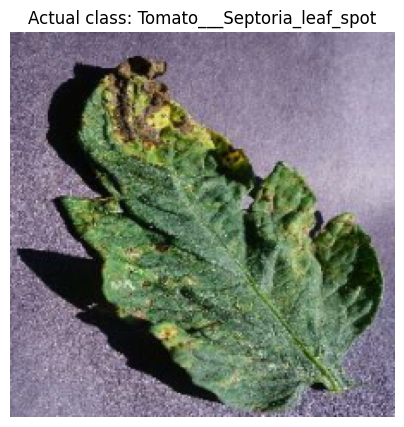

In [67]:
# Get one image from the test dataset

sample_images, sample_labels = next(iter(test_dataset))

sample_image = sample_images[0]
sample_label = sample_labels[0].numpy()

# Display the image
plt.figure(figsize=(5, 5))

# Convert the normalized image back to a displayable range
display_image = (sample_image.numpy() + 1) / 2

plt.imshow(display_image)
plt.title(f"Actual class: {class_names[sample_label]}")
plt.axis("off")
plt.show()

In [68]:
# Predict the class of the sample image

sample_prediction = model.predict(
    np.expand_dims(sample_image.numpy(), axis=0),
    verbose=0
)

predicted_index = np.argmax(sample_prediction[0])
predicted_class = class_names[predicted_index]
confidence = sample_prediction[0][predicted_index] * 100

print("Actual class:", class_names[sample_label])
print("Predicted class:", predicted_class)
print(f"Confidence: {confidence:.2f}%")

Actual class: Tomato___Septoria_leaf_spot
Predicted class: Tomato___Septoria_leaf_spot
Confidence: 74.39%


### **Interpretation of Prediction Result**

The model correctly classified the test image as **Tomato___Septoria_leaf_spot**, which matches its actual label. The confidence score was **74.39%**.

The prediction is correct, but the confidence is moderate rather than very high. Septoria leaf spot produces small dark spots that look similar to other tomato diseases such as Target Spot and Early Blight, so the model spread some of its probability across those similar classes.

This shows why the application should display the confidence score, and ideally the top three predictions, instead of only the top class. A farmer or extension officer can then see when the model is less certain and look more closely at the leaf.

### **5.4 Prediction from an Uploaded Image**

To support real-world use, the prediction function is designed to accept an image file uploaded by a user. The image is loaded from its file path, resized to the required 224 × 224 dimensions, and processed using the same MobileNetV2 preprocessing applied during training.

The processed image is then passed to the trained PhytoGuard AI model. The model returns the predicted plant disease or healthy class together with its confidence score.

In [70]:
# Upload an image for prediction

from ipywidgets import FileUpload
from IPython.display import display
import os

uploader = FileUpload(
    accept="image/*",
    multiple=False
)

display(uploader)

FileUpload(value=(), accept='image/*', description='Upload')

In [96]:
# Check the uploaded file
print("Number of uploaded files:", len(uploader.value))

if len(uploader.value) > 0:
    uploaded_file = uploader.value[0]
    print("Uploaded file:", uploaded_file["name"])
    print("File size:", uploaded_file["size"], "bytes")
else:
    print("No file uploaded yet.")

Number of uploaded files: 1
Uploaded file: LeafImage2.jpg
File size: 36650 bytes


In [97]:
# Save the uploaded image to the Kaggle working directory

uploaded_file = uploader.value[0]

uploaded_image_path = uploaded_file["name"]

with open(uploaded_image_path, "wb") as f:
    f.write(uploaded_file["content"])

print("Image saved successfully!")
print("Image path:", uploaded_image_path)

Image saved successfully!
Image path: LeafImage2.jpg


In [98]:
# Predict the uploaded leaf image

result = predict_image(uploaded_image_path, model, class_names)

print("Predicted class:", result["predicted_class"])
print(f"Confidence: {result['confidence']:.2f}%")

print("\nTop 3 predictions:")
for rank, prediction in enumerate(result["top_predictions"], start=1):
    print(f"{rank}. {prediction['class']} - {prediction['confidence']:.2f}%")

Predicted class: Tomato___Late_blight
Confidence: 83.00%

Top 3 predictions:
1. Tomato___Late_blight - 83.00%
2. Tomato___Early_blight - 9.46%
3. Pepper,_bell___Bacterial_spot - 5.88%


### **Interpretation of Uploaded Image Prediction**

The uploaded image (LeafImage2.jpg) is a real tomato leaf photographed outdoors, not an image from the PlantVillage dataset. The model predicted **Tomato___Late_blight** with **83.00%** confidence, followed by Tomato___Early_blight at **9.46%** and Pepper,_bell___Bacterial_spot at **5.88%**.

The true label of this image is not confirmed. However, the lesion shows faint concentric rings surrounded by a yellow halo, which is a typical sign of **Early blight** rather than Late blight. If so, the model's top prediction is incorrect and the correct class was ranked second.

A likely reason is the difference between the training data and this photo. PlantVillage images were captured under controlled conditions, with a single leaf on a plain background and even lighting. This photo has strong sunlight, sharp shadows, a dark plastic background and a large dried, curled area at the leaf edge. The model has never seen conditions like these, so it is less reliable on them. This is known as **domain shift**.

This result shows two things. First, the full prediction pipeline works on an image from outside the dataset: the file is resized to 224 × 224, processed with MobileNetV2 preprocessing and classified by the saved model. Second, the 96.11% test accuracy applies to images similar to PlantVillage and may not hold in the field. This is exactly why the retraining feature matters: as users upload correctly labelled field photos, the model can be retrained to handle real-world conditions better.

## **6. Model Retraining**

A deployed model needs to improve as new data becomes available. The retraining process in PhytoGuard AI works as follows:

1. **New data arrives.** Users upload labelled images, organised into one folder per class.
2. **A trigger decides whether to retrain.** Retraining starts automatically when enough new images have been uploaded, or immediately when a user presses the retrain button.
3. **The current model is fine-tuned.** It is trained further on the new images, mixed with a sample of the original training images so it does not forget what it has already learned.
4. **The new model is compared with the current one.** Both models are evaluated on the same unseen test set.
5. **The better model is kept.** The new model only replaces the current one if its test accuracy is at least as high. The old model is archived and every retraining run is logged.

These same functions will be reused in `src/retrain.py` and called by the API when a user triggers retraining from the application.

### **6.1 Preparing the Data Folders**

The project stores image data in class folders, which is also the format users will follow when uploading new data:

- `data/train/`: a sample of original training images, used as replay data during retraining so the model keeps its existing knowledge.
- `data/test/`: a sample of unseen test images, used for demonstrating predictions in the application.
- `data/retrain/`: new labelled images. Here, images from the validation split are used to **simulate a bulk upload** from a user, since they were not used to update the model weights during training.

In [87]:
# Export sample images into class folders

TRAIN_DIR = "data/train"
TEST_DIR = "data/test"
RETRAIN_DIR = "data/retrain"

# Raw (unprocessed) versions of the three splits, using the same shuffled order as before
raw_train = shuffled_dataset.take(train_size)
raw_validation = shuffled_dataset.skip(train_size).take(validation_size)
raw_test = shuffled_dataset.skip(train_size + validation_size)


def export_images(raw_dataset, folder, per_class):
    """Save up to `per_class` raw images per class as JPEG files in class folders."""
    counts = np.zeros(total_classes, dtype=int)

    for image, label in raw_dataset:
        label = int(label.numpy())

        if counts[label] >= per_class:
            continue

        class_dir = os.path.join(folder, class_names[label])
        os.makedirs(class_dir, exist_ok=True)

        file_path = os.path.join(class_dir, f"img_{counts[label]:03d}.jpg")
        tf.io.write_file(file_path, tf.io.encode_jpeg(image, quality=95))

        counts[label] += 1

        if counts.min() >= per_class:
            break

    return counts


train_counts = export_images(raw_train, TRAIN_DIR, per_class=20)
test_counts = export_images(raw_test, TEST_DIR, per_class=10)
retrain_counts = export_images(raw_validation, RETRAIN_DIR, per_class=15)

print("Images exported to data/train:", train_counts.sum())
print("Images exported to data/test:", test_counts.sum())
print("Images exported to data/retrain (simulated upload):", retrain_counts.sum())
print("Smallest class in simulated upload:", retrain_counts.min(), "images")

Images exported to data/train: 760
Images exported to data/test: 380
Images exported to data/retrain (simulated upload): 570
Smallest class in simulated upload: 15 images


### **6.2 Loading Uploaded Images**

Uploaded images can come in different sizes and formats, so they are passed through exactly the same preprocessing as the training data: decoding, resizing to 224 × 224 and MobileNetV2 normalisation. Folders that do not match a known class name are skipped, so a mislabelled upload cannot break retraining.

In [88]:
# Functions for loading labelled images from class folders

VALID_EXTENSIONS = (".jpg", ".jpeg", ".png")


def load_labelled_folder(folder):
    """Return image paths and integer labels from a folder of class subfolders."""
    paths, labels = [], []

    if not os.path.isdir(folder):
        return paths, labels

    for class_name in sorted(os.listdir(folder)):
        class_dir = os.path.join(folder, class_name)

        if not os.path.isdir(class_dir):
            continue

        if class_name not in class_names:
            print("Skipping unknown class folder:", class_name)
            continue

        for file_name in sorted(os.listdir(class_dir)):
            if file_name.lower().endswith(VALID_EXTENSIONS):
                paths.append(os.path.join(class_dir, file_name))
                labels.append(class_names.index(class_name))

    return paths, labels


def load_and_preprocess(path, label):
    """Read an image file and apply the same preprocessing used in training."""
    image = tf.io.read_file(path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)
    return image, label


def build_dataset(paths, labels, training=False):
    """Create a batched tf.data pipeline from image paths and labels."""
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(len(paths), seed=42)

    ds = ds.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)

    if training:
        ds = ds.map(augment_image, num_parallel_calls=tf.data.AUTOTUNE)

    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


new_paths, new_labels = load_labelled_folder(RETRAIN_DIR)
print("New labelled images found:", len(new_paths))

New labelled images found: 570


### **6.3 Retraining Trigger**

Retraining can be started in two ways:

- **Automatic trigger:** when the number of newly uploaded images reaches a threshold (200 images), retraining starts without user action. Retraining on just a handful of images would cost compute time without meaningfully improving the model.
- **Manual trigger:** a user presses the retrain button in the application, which starts retraining immediately regardless of the threshold.

In [89]:
# Retraining trigger

RETRAIN_THRESHOLD = 200


def should_retrain(new_image_count, manual_trigger=False, threshold=RETRAIN_THRESHOLD):
    """Decide whether retraining should start, and explain why."""
    if manual_trigger:
        return True, "Manual retraining requested by the user."

    if new_image_count >= threshold:
        return True, f"{new_image_count} new images reached the threshold of {threshold}."

    return False, f"Only {new_image_count} new images. Retraining starts at {threshold}."


# Show how the trigger responds in different situations
print(should_retrain(50))
print(should_retrain(50, manual_trigger=True))
print(should_retrain(len(new_paths)))

(False, 'Only 50 new images. Retraining starts at 200.')
(True, 'Manual retraining requested by the user.')
(True, '570 new images reached the threshold of 200.')


### **Interpretation of the Retraining Trigger**

The trigger behaved correctly in all three test cases. With only 50 new images, it decided **not** to retrain, because the amount of new data was below the threshold of 200. When the manual trigger was used with the same 50 images, retraining was allowed straight away, as it would be when a user presses the retrain button. With the 570 images from the simulated upload, the threshold was passed and retraining was triggered automatically.

This gives the system two safe paths. Small uploads collect until there is enough data to make retraining worthwhile, while users can still start retraining on demand.

### **6.4 Retraining and Model Comparison**

The retraining function loads the current saved model, unfreezes the top 30 layers of MobileNetV2 and fine-tunes it with a small learning rate. The training data combines the new images with replay images from `data/train`, which reduces the risk of the model forgetting classes that are not in the new upload.

Before and after retraining, both models are evaluated on the same full test set. The new model only replaces the current one if its test accuracy is at least as high. The previous model is archived, and the result of every run is recorded in `models/retrain_log.json`.

In [91]:
# Retraining and promotion functions

import shutil
from sklearn.model_selection import train_test_split

ARCHIVE_DIR = os.path.join(MODEL_DIR, "archive")
RETRAIN_LOG_PATH = os.path.join(MODEL_DIR, "retrain_log.json")


def retrain_model(model_path, new_data_dir, replay_data_dir, test_ds,
                  epochs=3, learning_rate=1e-5, fine_tune_layers=30):
    """Fine-tune the saved model on new plus replay data and compare it with the current model."""

    # 1. Evaluate the current model as the baseline
    current_model = tf.keras.models.load_model(model_path)
    old_loss, old_accuracy = current_model.evaluate(test_ds, verbose=0)

    # 2. Combine new images with replay images
    new_p, new_l = load_labelled_folder(new_data_dir)
    replay_p, replay_l = load_labelled_folder(replay_data_dir)

    all_paths = new_p + replay_p
    all_labels = new_l + replay_l

    train_p, val_p, train_l, val_l = train_test_split(
        all_paths, all_labels, test_size=0.15, random_state=42
    )

    retrain_train_ds = build_dataset(train_p, train_l, training=True)
    retrain_val_ds = build_dataset(val_p, val_l, training=False)

    # 3. Load a fresh copy of the model and prepare it for fine-tuning
    candidate = tf.keras.models.load_model(model_path)
    base = next(layer for layer in candidate.layers if isinstance(layer, tf.keras.Model))
    base.trainable = True
    for layer in base.layers[:-fine_tune_layers]:
        layer.trainable = False

    candidate.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"]
    )

    retrain_history = candidate.fit(
        retrain_train_ds,
        validation_data=retrain_val_ds,
        epochs=epochs,
        callbacks=[tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=2, restore_best_weights=True
        )]
    )

    # 4. Evaluate the retrained model on the same test set
    new_loss, new_accuracy = candidate.evaluate(test_ds, verbose=0)

    results = {
        "timestamp": datetime.now().strftime("%Y-%m-%d %H:%M"),
        "new_images": len(new_p),
        "replay_images": len(replay_p),
        "epochs_run": len(retrain_history.history["loss"]),
        "old_test_loss": round(float(old_loss), 4),
        "old_test_accuracy": round(float(old_accuracy), 4),
        "new_test_loss": round(float(new_loss), 4),
        "new_test_accuracy": round(float(new_accuracy), 4)
    }

    return candidate, results, retrain_history


def promote_if_better(candidate, results, model_path):
    """Replace the current model only if the retrained model is at least as accurate."""
    promoted = results["new_test_accuracy"] >= results["old_test_accuracy"]

    if promoted:
        os.makedirs(ARCHIVE_DIR, exist_ok=True)
        archive_name = f"phytoguard_ai_{datetime.now().strftime('%Y%m%d_%H%M%S')}.h5"
        shutil.copy(model_path, os.path.join(ARCHIVE_DIR, archive_name))
        candidate.save(model_path)

    results["promoted"] = promoted

    # Append this run to the retraining log
    log = []
    if os.path.exists(RETRAIN_LOG_PATH):
        with open(RETRAIN_LOG_PATH) as f:
            log = json.load(f)
    log.append(results)
    with open(RETRAIN_LOG_PATH, "w") as f:
        json.dump(log, f, indent=2)

    return promoted

### **6.5 Running the Retraining Pipeline**

The full pipeline is run on the simulated upload: the trigger checks whether retraining is needed, the model is retrained, both models are compared on the test set, and the better one is kept.

In [92]:
# Run the full retraining pipeline

retrain_needed, reason = should_retrain(len(new_paths))
print("Trigger decision:", reason)

if not retrain_needed:
    # The simulated upload is below the threshold, so use the manual trigger,
    # as a user pressing the retrain button would
    retrain_needed, reason = should_retrain(len(new_paths), manual_trigger=True)
    print("Trigger decision:", reason)

if retrain_needed:
    candidate_model, retrain_results, retrain_history = retrain_model(
        model_path=FINAL_MODEL_PATH,
        new_data_dir=RETRAIN_DIR,
        replay_data_dir=TRAIN_DIR,
        test_ds=test_dataset
    )

    promoted = promote_if_better(candidate_model, retrain_results, FINAL_MODEL_PATH)

    print("\nRETRAINING RESULTS")
    print("------------------")
    print(json.dumps(retrain_results, indent=2))

    if promoted:
        print("\nThe retrained model was promoted and saved as the current model.")
    else:
        print("\nThe retrained model was not better, so the current model was kept.")

Trigger decision: 570 new images reached the threshold of 200.


Epoch 1/3
36/36 ━━━━━━━━━━━━━━━━━━━━ 41s 733ms/step - accuracy: 0.9265 - loss: 0.2533 - val_accuracy: 0.9450 - val_loss: 0.2151
Epoch 2/3
36/36 ━━━━━━━━━━━━━━━━━━━━ 7s 193ms/step - accuracy: 0.9407 - loss: 0.2038 - val_accuracy: 0.9450 - val_loss: 0.2105
Epoch 3/3
36/36 ━━━━━━━━━━━━━━━━━━━━ 7s 189ms/step - accuracy: 0.9451 - loss: 0.1903 - val_accuracy: 0.9550 - val_loss: 0.2050



RETRAINING RESULTS
------------------
{
  "timestamp": "2026-11-24 08:38",
  "new_images": 570,
  "replay_images": 760,
  "epochs_run": 3,
  "old_test_loss": 0.1262,
  "old_test_accuracy": 0.9611,
  "new_test_loss": 0.1237,
  "new_test_accuracy": 0.9632,
  "promoted": true
}

The retrained model was promoted and saved as the current model.


### **Interpretation of the Retraining Results**

The simulated upload contained **570 new images**, 15 for each of the 38 classes. These were combined with **760 replay images** from the original training data, and the model was fine-tuned for 3 epochs.

On the same test set of 5,431 images, the retrained model reached a **test accuracy of 96.32%**, compared with **96.11%** for the original model. Test loss also decreased slightly from **0.1262 to 0.1237**. Because the new model was at least as accurate, it was **promoted** and saved as the current model, the previous model was archived in `models/archive/`, and the run was recorded in `models/retrain_log.json`.

The improvement is small, about 11 more test images classified correctly, and should not be overstated. Only 570 new images were added to a model already trained on more than 43,000, so a large gain was not expected. A larger or more targeted upload, for example more images of Tomato Early blight or the two corn leaf diseases identified in Section 4.8, would be more likely to produce a meaningful improvement.

The more important result is that the retraining process works safely from start to finish. New data is loaded with the same preprocessing as training, replay data protects existing knowledge, both models are compared on the same unseen test set, and a retrained model can only replace the current one if it performs at least as well. If retraining had made the model worse, the original would have been kept automatically.

In [93]:
# Update the stored metrics if the retrained model was promoted

if retrain_needed and promoted:
    with open(METRICS_PATH) as f:
        current_metrics = json.load(f)

    current_metrics.update({
        "model_version": f"v{len(json.load(open(RETRAIN_LOG_PATH))) + 1}",
        "trained_on": retrain_results["timestamp"],
        "test_loss": retrain_results["new_test_loss"],
        "test_accuracy": retrain_results["new_test_accuracy"],
        "note": "Precision, recall and F1 values are from the previous version until the next full evaluation."
    })

    with open(METRICS_PATH, "w") as f:
        json.dump(current_metrics, f, indent=2)

    print(json.dumps(current_metrics, indent=2))

{
  "model_version": "v2",
  "trained_on": "2026-11-24 08:38",
  "test_loss": 0.1237,
  "test_accuracy": 0.9632,
  "weighted_precision": 0.962,
  "weighted_recall": 0.9611,
  "weighted_f1": 0.9604,
  "macro_f1": 0.9507,
  "note": "Precision, recall and F1 values are from the previous version until the next full evaluation."
}


## **7. From Notebook to Production, and Conclusion**

### **7.1 Serving the Model**

The trained model is saved as `models/phytoguard_ai_final.h5`. For deployment, it is split into two parts with `python -m src.model --export`:

- a **TensorFlow Lite feature extractor** (MobileNetV2 up to global average pooling), and
- the **weights of the final softmax layer**, stored with NumPy.

Together they give the same predictions as the Keras model (maximum probability difference of 0.000003, with 100% agreement on the predicted class), but the API only needs about 190 MB of memory instead of about 730 MB with full TensorFlow. This allows the API and dashboard to run on a small cloud instance.

In the deployed application, retraining follows the same logic as Section 6: new uploads are combined with replay images, the old and new models are compared on the same held-out images, and the new model is only promoted if it is at least as accurate. To keep retraining fast on a small instance, production retraining updates the final classification layer on top of the frozen MobileNetV2 features, while full fine-tuning is done offline as in Section 6.

### **7.2 Conclusion**

- The fine-tuned MobileNetV2 model reached **96.11% test accuracy** and a **macro F1-score of 95.07%** on 5,431 unseen images, and **96.32%** after retraining on new data.
- The feature analysis showed that **colour** is the clearest visible sign of disease, while whole-image **texture** is not enough, which supports the use of a CNN.
- The model's errors are concentrated in visually similar diseases of the **same crop**, especially tomato and corn. Tomato Early blight has the lowest recall (56.70%).
- A real outdoor photo was misclassified, which shows that the model is less reliable on field images than on PlantVillage images.

**Next steps:** collect labelled field photos through the application's upload feature, prioritise the weakest classes (Tomato Early blight, Corn Cercospora leaf spot and Tomato Target Spot), and use the retraining pipeline to adapt the model to real-world conditions.
